# Plot Waveforms for ROMY Events

This notebook reads an event list file, loads data for each event, and creates a plot showing waveforms sorted by epicentral distance.

## Notebook Overview
This notebook inspects one selected event in detail using waveform and polarization-oriented visualizations.

**Main workflow**
- Load one event configuration and corresponding waveforms.
- Apply targeted preprocessing/rotation/filtering.
- Plot detailed component waveforms and zoom windows.
- Optimize the SH backazimuth in the S-wave window and compare it with the catalog backazimuth.
- Compute and visualize polarization-related diagnostics.
- Save event-specific detail figures.

In [17]:
import os
import yaml
import numpy as np
import matplotlib.pyplot as plt

from obspy import UTCDateTime
from sixdegrees.sixdegrees import sixdegrees
from obspy import Stream
from obspy.taup import TauPyModel

os.makedirs("./output/figures/event", exist_ok=True)


## Single-event P/S zoom: Love and Rayleigh overlays

This section loads one event (default `2025-05-13`) and plots P- and S-wave zoom windows.

- Top row: Love-wave proxy (`a_T` with `$\dot\omega_Z$`)
- Bottom row: Rayleigh-wave proxy (`a_Z` with `$\dot\omega_T$`)
- Translation in black, rotation in red
- Rotation uses a second y-axis with the same numeric y-limits as translation

In [18]:
# -------------------------
# User setting (default)
# -------------------------
# format: YYYY-MM-DD
event_date = "2025-06-02"  #good
# event_date = "2025-12-27"  #good
# event_date = "2025-05-13"  #good
# event_date = "2023-09-08"  #ok
# event_date = "2025-12-12"  #ok

event_id = event_date.replace("-", "")

# Window lengths around expected arrivals [seconds]
p_window = (-50, 120)
s_window = (-50, 120)

# Select which arrivals to show on plots
# Examples: ["P", "S"], ["P", "PP", "S", "SS"]
arrivals_to_show = ["P", "PP", "S", "SS"] # , "pP", "pS"]
arrivals_to_show = ["P","S"]

# Time shifts applied to plotted arrival markers [s]
p_arrival_shift_s = -5.0
s_arrival_shift_s = -5.0

earth_model = "prem"

fmin, fmax = 0.01, 0.1

In [19]:
# -------------------------
# User setting (default)
# -------------------------
# format: YYYY-MM-DD
event_date = "2025-05-13"  #good

event_id = event_date.replace("-", "")

# Window lengths around expected arrivals [seconds]
p_window = (-50, 120)
s_window = (-50, 120)

# Select which arrivals to show on plots
# Examples: ["P", "S"], ["P", "PP", "S", "SS"]
arrivals_to_show = ["P", "PP", "S", "SS"]

# Time shifts applied to plotted arrival markers [s]
p_arrival_shift_s = -10.0
s_arrival_shift_s = -10.0

earth_model = "prem"

fmin, fmax = 0.01, 0.1

In [20]:
# -------------------------
# User setting (default)
# -------------------------
# format: YYYY-MM-DD
event_date = "2023-09-08"  #ok

event_id = event_date.replace("-", "")

# Window lengths around expected arrivals [seconds]
p_window = (-50, 120)
s_window = (-50, 120)

# Select which arrivals to show on plots
# Examples: ["P", "S"], ["P", "PP", "S", "SS"]
arrivals_to_show = ["P", "PP", "S", "SS"] # , "pP", "pS"]
arrivals_to_show = ["P","S"]

# Time shifts applied to plotted arrival markers [s]
p_arrival_shift_s = -10.0
s_arrival_shift_s = -10.0

earth_model = "prem"

fmin, fmax = 0.01, 0.1

In [21]:
# -------------------------
# Load one event
# -------------------------
config_path = f"./events/event_{event_id}/config_romy_{event_id}.yml"
if not os.path.exists(config_path):
    config_path = f"./events/event_{event_id}/config_{event_id}.yml"
if not os.path.exists(config_path):
    raise FileNotFoundError(f"No config found for event {event_date} ({event_id})")

config = sixdegrees.load_from_yaml(config_path)

# set fmin, fmax
config["fmin"] = fmin
config["fmax"] = fmax

sd = sixdegrees(conf=config)

ev = sd.get_event_info(
    origin_time=config["origin_time"],
    base_catalog="USGS",
    magnitude=config.get("magnitude", None),
)

sd.load_data(config["tbeg"], config["tend"], resample_rate=5)
sd.trim_stream(set_common=True, set_interpolate=False)
sd.filter_data(fmin=config["fmin"], fmax=config["fmax"], output=False)

if "pol_dict" in config:
    sd.polarity_stream(pol_dict=config["pol_dict"], raw=True)
else:
    sd.polarity_stream(pol_dict={"HZ": -1, "JZ": 1}, raw=True)

if "time_cuts" in config:
    for key, values in config["time_cuts"].items():
        for value in values:
            sd.replace_values_in_window(
                tbeg=value[0], tend=value[1], value=0, channel_list=[key]
            )

st = sd.st.copy()
origin_time = UTCDateTime(config["origin_time"])


Found event:
Origin time: 2023-09-08T22:11:01.405000Z
Magnitude: 6.8 mww
Location: 31.058°N, -8.385°E
Depth: 19.0 km
Epicentral Distance: 2526.01 km
Epicentral Distance: 22.7°
Backazimuth: 228.40°
-> fetching XX.ROMY..BHZ data from mseed file
-> fetching XX.ROMY..BHN data from mseed file
-> fetching XX.ROMY..BHE data from mseed file
3 Trace(s) in Stream:
XX.ROMY..BHZ | 2023-09-08T22:14:28.990000Z - 2023-09-08T22:43:00.990000Z | 20.0 Hz, 34241 samples
XX.ROMY..BHN | 2023-09-08T22:14:28.990000Z - 2023-09-08T22:43:00.990000Z | 20.0 Hz, 34241 samples
XX.ROMY..BHE | 2023-09-08T22:14:28.990000Z - 2023-09-08T22:43:00.990000Z | 20.0 Hz, 34241 samples
-> fetching XX.ROMY..BJZ data from mseed file
-> fetching XX.ROMY..BJN data from mseed file
-> fetching XX.ROMY..BJE data from mseed file
3 Trace(s) in Stream:
XX.ROMY..BJZ | 2023-09-08T22:14:29.011600Z - 2023-09-08T22:43:01.011600Z | 20.0 Hz, 34241 samples
XX.ROMY..BJN | 2023-09-08T22:14:28.999399Z - 2023-09-08T22:43:00.999399Z | 20.0 Hz, 34241 s

In [22]:
# -------------------------
# Build required traces
# -------------------------
baz = ev.get("backazimuth", None)
if baz is None:
    raise ValueError("Backazimuth missing in event info; cannot rotate NE->RT")

# Translation NE -> RT
tra_n = st.select(channel="*HN")
tra_e = st.select(channel="*HE")
if len(tra_n) == 0 or len(tra_e) == 0:
    raise ValueError("Missing HN/HE traces for translation rotation to T")

tra_ne = Stream([tra_n[0].copy(), tra_e[0].copy()])
tra_rt = tra_ne.copy()
tra_rt.rotate("NE->RT", back_azimuth=baz)
tra_t = tra_rt.select(channel="*T")
if len(tra_t) == 0:
    raise ValueError("No translation T component after rotation")
tra_t = tra_t[0]

# Rotation NE -> RT
rot_n = st.select(channel="*JN")
rot_e = st.select(channel="*JE")
if len(rot_n) == 0 or len(rot_e) == 0:
    raise ValueError("Missing JN/JE traces for rotation rotation to T")

rot_ne = Stream([rot_n[0].copy(), rot_e[0].copy()])
rot_rt = rot_ne.copy()
rot_rt.rotate("NE->RT", back_azimuth=baz)
rot_t = rot_rt.select(channel="*T")
if len(rot_t) == 0:
    raise ValueError("No rotation T component after rotation")
rot_t = rot_t[0]

rot_z = st.select(channel="*JZ")
if len(rot_z) == 0:
    raise ValueError("Missing JZ trace for rotation vertical")
rot_z = rot_z[0]

tra_z = st.select(channel="*HZ")
if len(tra_z) == 0:
    raise ValueError("Missing HZ trace for translation vertical")
tra_z = tra_z[0]


In [23]:
# -------------------------
# Expected arrivals for provided phase list
# -------------------------
distance_km = ev.get("distance_km", np.nan)
distance_deg = ev.get("distance_deg", distance_km / 111.19 if np.isfinite(distance_km) else np.nan)
depth_km = ev.get("depth_km", ev.get("depth", 10.0))

# Normalize and deduplicate requested phases while preserving order
arrivals_to_show = [str(ph).strip() for ph in arrivals_to_show if str(ph).strip()]
arrivals_to_show = list(dict.fromkeys(arrivals_to_show))

# Keep user labels, but also support case variants for TauP lookup
def _phase_candidates(phase):
    cands = [phase]
    up = phase.upper()
    lo = phase.lower()
    if up not in cands:
        cands.append(up)
    if lo not in cands:
        cands.append(lo)
    return cands

arrivals_map = {ph: np.nan for ph in arrivals_to_show}

if not np.isfinite(distance_deg):
    raise ValueError("Invalid epicentral distance; cannot compute travel times.")

model = TauPyModel(model=earth_model)
for ph in arrivals_to_show:
    for cand in _phase_candidates(ph):
        try:
            arrs = model.get_travel_times(
                source_depth_in_km=float(depth_km),
                distance_in_degree=float(distance_deg),
                phase_list=[cand],
            )
            if arrs:
                arrivals_map[ph] = arrs[0].time
                break
        except Exception:
            continue

# Anchor arrivals for panel windows: prefer P/S, otherwise first valid P*/S* phase
p_family_arrivals = {ph: arrivals_map[ph] for ph in arrivals_to_show if ph.upper().startswith("P")}
s_family_arrivals = {ph: arrivals_map[ph] for ph in arrivals_to_show if ph.upper().startswith("S")}

p_arrival_s = arrivals_map.get("P", arrivals_map.get("p", np.nan))
s_arrival_s = arrivals_map.get("S", arrivals_map.get("s", np.nan))

if not np.isfinite(p_arrival_s):
    for ph, arr in p_family_arrivals.items():
        if np.isfinite(arr):
            p_arrival_s = arr
            break

if not np.isfinite(s_arrival_s):
    for ph, arr in s_family_arrivals.items():
        if np.isfinite(arr):
            s_arrival_s = arr
            break

if not np.isfinite(p_arrival_s) or not np.isfinite(s_arrival_s):
    raise ValueError(
        "Could not estimate anchor arrivals for P* and/or S* phases. "
        "Make sure arrivals_to_show contains at least one valid P* and one valid S* phase."
    )

print(f"Event: {event_date}")
print(f"Distance: {distance_km:.1f} km ({distance_deg:.2f} deg)")
print(f"Expected anchor arrivals (s after origin): P={p_arrival_s:.1f}, S={s_arrival_s:.1f}")
shown = [f"{ph}={arrivals_map[ph]:.1f}s" for ph in arrivals_to_show if np.isfinite(arrivals_map[ph])]
missing = [ph for ph in arrivals_to_show if not np.isfinite(arrivals_map[ph])]
print(f"Shown arrivals: {shown}")
if missing:
    print(f"Missing arrivals (not found): {missing}")




Event: 2023-09-08
Distance: 2526.0 km (22.72 deg)
Expected anchor arrivals (s after origin): P=300.0, S=551.0
Shown arrivals: ['P=300.0s', 'S=551.0s']


In [49]:
def rel_time_seconds(tr):
    return np.array(tr.times()) + (tr.stats.starttime - origin_time)


def plot_overlay(ax, tra_trace, rot_trace, anchor_arrival_s, window, title, y_label_left, y_label_right, phase_family, arrivals_map, arrival_shift_s=0.0, factor=3.5):
    t_tra = rel_time_seconds(tra_trace)
    t_rot = rel_time_seconds(rot_trace)

    w0 = anchor_arrival_s + window[0]
    w1 = anchor_arrival_s + window[1]

    m_tra = (t_tra >= w0) & (t_tra <= w1)
    m_rot = (t_rot >= w0) & (t_rot <= w1)

    x_tra = t_tra[m_tra] - anchor_arrival_s
    y_tra = tra_trace.data[m_tra] * 1e6  # um/s^2
    x_rot = t_rot[m_rot] - anchor_arrival_s
    y_rot = rot_trace.data[m_rot] * 1e9 * factor  # nrad/s, scaled for visibility

    ax.plot(x_tra, y_tra, color="black", lw=1.2, label="Translation")
    ax2 = ax.twinx()
    ax2.plot(x_rot, y_rot, color="darkred", lw=1.2, label="Rotation")

    # Align both y-axes to identical numeric limits
    absmax = np.nanmax(np.abs(np.concatenate([y_tra, y_rot])))
    if not np.isfinite(absmax) or absmax == 0:
        absmax = 1.0
    ax.set_ylim(-absmax, absmax)
    ax2.set_ylim(-absmax, absmax)

    # Plot only arrivals of requested phase family in this panel
    family = phase_family.upper()
    family_color = "green" if family.startswith("P") else "blue"
    family_arrivals = [(ph, arr) for ph, arr in arrivals_map.items() if ph.upper().startswith(family)]

    label_idx = 0
    for ph, arr in family_arrivals:
        if not np.isfinite(arr):
            continue

        # Apply user shift to all arrivals of the current family (P* or S*)
        shifted_arr = arr + arrival_shift_s
        x_rel = shifted_arr - anchor_arrival_s
        if x_rel < window[0] or x_rel > window[1]:
            continue

        ls = "--"
        lw = 1.2
        ax.axvline(x_rel, color=family_color, ls=ls, lw=lw, alpha=0.95)

        y_text = absmax * (0.90 - 0.10 * min(label_idx, 6))
        ax.text(x_rel + 2, y_text, f"{ph}", va="top", ha="left", fontsize=12, fontweight="bold", zorder=10, color=family_color)
        label_idx += 1

    # Indicate applied shift and rotation scale
    ax.text(0.03, 0.1, f"shift: {arrival_shift_s:+.0f} s", transform=ax.transAxes,
            va="top", ha="left", fontsize=11, color=family_color)
    ax.text(0.98, 0.95, f"x{factor}", transform=ax.transAxes, va="top", ha="right", fontsize=13, color="darkred")
    
    # Peak values in current window (shown in lower-right)
    peak_acc = np.nanmax(np.abs(y_tra)) if y_tra.size else np.nan
    peak_rot = np.nanmax(np.abs(y_rot)) if y_rot.size else np.nan
    peak_text = f"peak |a|: {peak_acc:.2f} μm/s²\npeak |ω̇|: {peak_rot:.2f} nrad/s"
    ax.text(
        0.68,
        0.04,
        peak_text,
        transform=ax.transAxes,
        va="bottom",
        ha="left",
        fontsize=10,
        color="black",
        bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="0.7", alpha=0.8),
    )

    ax.set_title(title, fontsize=14)
    ax.set_ylabel(y_label_left, color="black", fontsize=13)
    ax2.set_ylabel(y_label_right, color="darkred", fontsize=13)
    ax.tick_params(axis="y", colors="black", labelsize=12)
    ax2.tick_params(axis="y", colors="darkred", labelsize=12)
    ax.tick_params(axis="x", labelsize=12)
    ax.grid(True, alpha=0.3, ls="--")

    return ax2


In [50]:
vfactor = 4.1

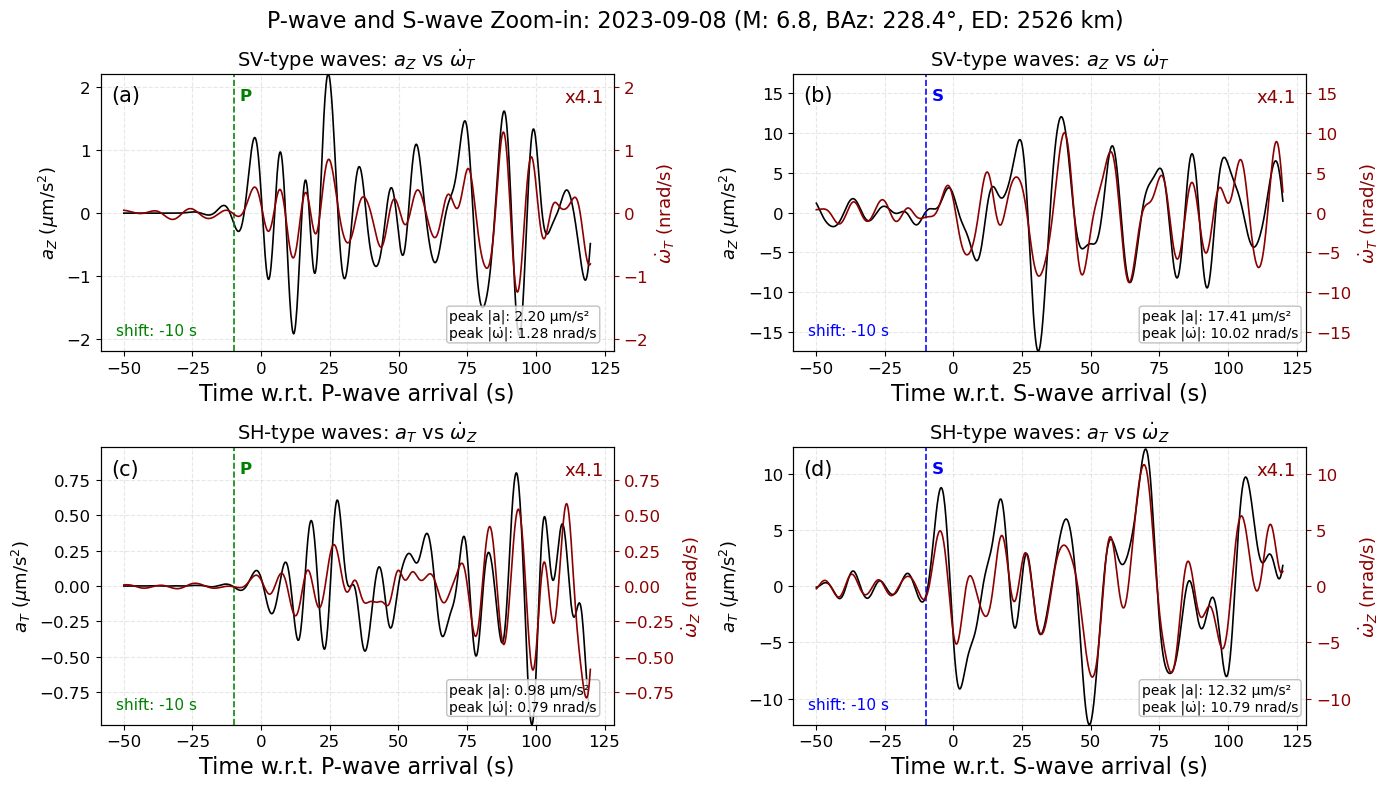

In [51]:
fig, axes = plt.subplots(2, 2, figsize=(14, 8), sharex=False)

# Top row: SV-type waves (translation Z + rotation T)
plot_overlay(
    axes[0, 0],
    tra_z,
    rot_t,
    p_arrival_s,
    p_window,
    "SV-type waves: $a_Z$ vs $\dot{\omega}_T$",
    "$a_Z$ ($\mu$m/s$^2$)",
    "$\dot{\omega}_T$ (nrad/s)",
    "P",
    arrivals_map,
    p_arrival_shift_s,
    vfactor,
)

plot_overlay(
    axes[0, 1],
    tra_z,
    rot_t,
    s_arrival_s,
    s_window,
    "SV-type waves: $a_Z$ vs $\dot{\omega}_T$",
    "$a_Z$ ($\mu$m/s$^2$)",
    "$\dot{\omega}_T$ (nrad/s)",
    "S",
    arrivals_map,
    s_arrival_shift_s,
    vfactor,
)


# Bottom row: SH-type waves (translation T + rotation Z)
plot_overlay(
    axes[1, 0],
    tra_t,
    rot_z,
    p_arrival_s,
    p_window,
    "SH-type waves: $a_T$ vs $\dot{\omega}_Z$",
    "$a_T$ ($\mu$m/s$^2$)",
    "$\dot{\omega}_Z$ (nrad/s)",
    "P",
    arrivals_map,
    p_arrival_shift_s,
    vfactor,
)

plot_overlay(
    axes[1, 1],
    tra_t,
    rot_z,
    s_arrival_s,
    s_window,
    "SH-type waves: $a_T$ vs $\dot{\omega}_Z$",
    "$a_T$ ($\mu$m/s$^2$)",
    "$\dot{\omega}_Z$ (nrad/s)",
    "S",
    arrivals_map,
    s_arrival_shift_s,
    vfactor,
)

axes[1, 0].set_xlabel("Time w.r.t. P-wave arrival (s)", fontsize=16)
axes[1, 1].set_xlabel("Time w.r.t. S-wave arrival (s)", fontsize=16)
axes[0, 0].set_xlabel("Time w.r.t. P-wave arrival (s)", fontsize=16)
axes[0, 1].set_xlabel("Time w.r.t. S-wave arrival (s)", fontsize=16)

axes[0, 0].text(0.02, 0.96, f"(a)", transform=axes[0, 0].transAxes,
            va="top", ha="left", fontsize=15, color="black")
axes[0, 1].text(0.02, 0.96, f"(b)", transform=axes[0, 1].transAxes,
            va="top", ha="left", fontsize=15, color="black")
axes[1, 0].text(0.02, 0.96, f"(c)", transform=axes[1, 0].transAxes,
            va="top", ha="left", fontsize=15, color="black")
axes[1, 1].text(0.02, 0.96, f"(d)", transform=axes[1, 1].transAxes,
            va="top", ha="left", fontsize=15, color="black")

# add baz, magnitue and epicentral distance ED to title
fig.suptitle(f"P-wave and S-wave Zoom-in: {event_date} (M: {config['magnitude']:.1f}, BAz: {baz:.1f}°, ED: {distance_km:.0f} km)", fontsize=16)
plt.tight_layout()
plt.show()

fig.savefig(f"./output/figures/event/event_{event_date}_P_S_zoom.png", dpi=150, bbox_inches="tight")


## SH-optimized backazimuth

For the S-wave window, search backazimuth to maximize the zero-lag correlation of transverse acceleration and vertical rotation rate, and compare that direction with the catalog backazimuth.

In [ ]:
# -------------------------------------------------------------------------
# Optimize SH correlation (panel d): a_T(baz) vs ω̇_Z in the S-wave window
# BAz from NE→RT; incidence from SH plane-wave relation a_T ≈ ±2 (β/sin i) ω̇_Z
# -------------------------------------------------------------------------
from scipy.stats import linregress

# Search ranges
baz_grid_deg = np.arange(0.0, 360.0, 1.0)
inc_grid_deg = np.arange(1.0, 80.0, 1.0)

# Local S velocity (km/s) used to map apparent velocity → incidence
beta_km_s = 3.5

# S-window used in panel (d)
anchor_s = s_arrival_s
win0, win1 = s_window
w0 = anchor_s + win0
w1 = anchor_s + win1

tr_n = tra_n[0]
tr_e = tra_e[0]
tr_jz = rot_z

t_n = rel_time_seconds(tr_n)
t_e = rel_time_seconds(tr_e)
t_jz = rel_time_seconds(tr_jz)

m_n = (t_n >= w0) & (t_n <= w1)
m_e = (t_e >= w0) & (t_e <= w1)
m_jz = (t_jz >= w0) & (t_jz <= w1)

n_samp = min(m_n.sum(), m_e.sum(), m_jz.sum())
a_n = tr_n.data[m_n][:n_samp]
a_e = tr_e.data[m_e][:n_samp]
w_z = tr_jz.data[m_jz][:n_samp]
t_rel = t_n[m_n][:n_samp] - anchor_s


def a_T_from_baz(baz_deg, a_n, a_e):
    """ObsPy NE→RT transverse: T = -N sin(baz) + E cos(baz)."""
    baz_r = np.deg2rad(baz_deg)
    return -a_n * np.sin(baz_r) + a_e * np.cos(baz_r)


def zero_lag_cc(x, y):
    x = np.asarray(x, dtype=float) - np.nanmean(x)
    y = np.asarray(y, dtype=float) - np.nanmean(y)
    denom = np.sqrt(np.nansum(x * x) * np.nansum(y * y))
    if not np.isfinite(denom) or denom == 0:
        return np.nan
    return float(np.nansum(x * y) / denom)


# --- 1) Backazimuth: maximize |CC| between a_T and ω̇_Z ---
cc_vs_baz = np.array([zero_lag_cc(a_T_from_baz(b, a_n, a_e), w_z) for b in baz_grid_deg])
i_baz = int(np.nanargmax(np.abs(cc_vs_baz)))
baz_opt = float(baz_grid_deg[i_baz])
cc_baz_opt = float(cc_vs_baz[i_baz])
a_t_opt = a_T_from_baz(baz_opt, a_n, a_e)

a_t_cat = a_T_from_baz(baz, a_n, a_e)
cc_cat = zero_lag_cc(a_t_cat, w_z)

# --- 2) Incidence: a_T ≈ sign * 2 * (β / sin i) * ω̇_Z ---
a_t0 = a_t_opt - np.nanmean(a_t_opt)
w_z0 = w_z - np.nanmean(w_z)
slope = linregress(w_z0, a_t0).slope
c_app_km_s = abs(slope) / 2.0 / 1e3 if np.isfinite(slope) else np.nan

rmse_vs_inc = np.full(inc_grid_deg.shape, np.nan)
for j, inc_try in enumerate(inc_grid_deg):
    s = np.sin(np.deg2rad(inc_try))
    c_app = (beta_km_s / s) * 1e3  # m/s
    scale = (np.sign(slope) if np.isfinite(slope) else -1.0) * 2.0 * c_app
    pred = scale * w_z0
    ref = np.nanstd(a_t0)
    if not np.isfinite(ref) or ref == 0:
        continue
    rmse_vs_inc[j] = np.sqrt(np.nanmean((a_t0 - pred) ** 2)) / ref

i_inc = int(np.nanargmin(rmse_vs_inc))
inc_opt = float(inc_grid_deg[i_inc])

if np.isfinite(c_app_km_s) and c_app_km_s > 0:
    sin_i = np.clip(beta_km_s / c_app_km_s, -1.0, 1.0)
    inc_from_capp = float(np.rad2deg(np.arcsin(sin_i)))
else:
    inc_from_capp = np.nan

baz_delta = ((baz_opt - baz + 180.0) % 360.0) - 180.0

print("SH (panel d) optimization — S-wave window")
print(f"  catalog BAz                = {baz:.1f}°")
print(f"  optimal BAz                = {baz_opt:.1f}°  (Δ = {baz_delta:+.1f}°)")
print(f"  optimal incidence          = {inc_opt:.1f}°  (min RMSE, β={beta_km_s} km/s)")
print(f"  incidence from c_app       = {inc_from_capp:.1f}°  (sin i = β/c_app)")
print(f"  CC (catalog BAz)           = {cc_cat:+.3f}")
print(f"  CC (optimal BAz)           = {cc_baz_opt:+.3f}")
print(f"  apparent |c| (a_T≈±2c ω̇_Z) = {c_app_km_s:.2f} km/s")

# --- Plot ---
fig_opt, axes_opt = plt.subplots(1, 3, figsize=(15, 4.2))

ax = axes_opt[0]
ax.plot(baz_grid_deg, cc_vs_baz, color="steelblue", lw=1.2)
ax.axvline(baz, color="gray", ls="--", lw=1.2, label=f"catalog {baz:.0f}°")
ax.axvline(baz_opt, color="crimson", ls="-", lw=1.4, label=f"opt {baz_opt:.0f}°")
ax.set_xlabel("Backazimuth (°)")
ax.set_ylabel("Zero-lag CC ($a_T$, $\\dot{\\omega}_Z$)")
ax.set_title("(a) CC vs backazimuth")
ax.set_xlim(0, 360)
ax.grid(True, alpha=0.3, ls="--")
ax.legend(fontsize=9, loc="best")

ax = axes_opt[1]
ax.plot(inc_grid_deg, rmse_vs_inc, color="darkorange", lw=1.2)
ax.axvline(inc_opt, color="crimson", ls="-", lw=1.4, label=f"opt {inc_opt:.0f}°")
if np.isfinite(inc_from_capp):
    ax.axvline(inc_from_capp, color="gray", ls="--", lw=1.2, label=f"from $c_a$ {inc_from_capp:.0f}°")
ax.set_xlabel("Incident angle (°)")
ax.set_ylabel("Normalized RMSE")
ax.set_title(f"(b) SH fit vs incidence (β={beta_km_s} km/s)")
ax.set_xlim(0, 80)
ax.grid(True, alpha=0.3, ls="--")
ax.legend(fontsize=9, loc="best")

ax = axes_opt[2]
y_tra_cat = a_t_cat * 1e6
y_tra_opt = a_t_opt * 1e6
y_rot = w_z * 1e9 * vfactor
s_opt = np.sin(np.deg2rad(inc_opt))
c_app_opt = (beta_km_s / s_opt) * 1e3
scale_opt = (np.sign(slope) if np.isfinite(slope) else -1.0) * 2.0 * c_app_opt
y_tra_pred = scale_opt * w_z0 * 1e6

ax.plot(t_rel, y_tra_cat, color="0.55", lw=1.0, label="$a_T$ catalog BAz")
ax.plot(t_rel, y_tra_opt, color="black", lw=1.2, label=f"$a_T$ opt BAz={baz_opt:.0f}°")
ax.plot(t_rel, y_tra_pred, color="tab:green", lw=1.0, ls="--",
        label=f"$\\pm 2(\\beta/\\sin i)\\,\\dot{{\\omega}}_Z$ (i={inc_opt:.0f}°)")
ax2 = ax.twinx()
ax2.plot(t_rel, y_rot, color="darkred", lw=1.2, label="$\\dot{\\omega}_Z$")
absmax = np.nanmax(np.abs(np.concatenate([y_tra_cat, y_tra_opt, y_rot, y_tra_pred])))
if not np.isfinite(absmax) or absmax == 0:
    absmax = 1.0
ax.set_ylim(-absmax, absmax)
ax2.set_ylim(-absmax, absmax)
ax.axvline(s_arrival_shift_s, color="blue", ls="--", lw=1.2, alpha=0.9)
ax.set_xlabel("Time w.r.t. S-wave arrival (s)")
ax.set_ylabel("$a_T$ ($\\mu$m/s$^2$)", color="black")
ax2.set_ylabel("$\\dot{\\omega}_Z$ (nrad/s)", color="darkred")
ax.set_title(f"(c) SH waveforms (CC={cc_baz_opt:+.2f})")
ax.grid(True, alpha=0.3, ls="--")
ax.tick_params(axis="y", colors="black")
ax2.tick_params(axis="y", colors="darkred")
lines1, labels1 = ax.get_legend_handles_labels()
lines2, labels2 = ax2.get_legend_handles_labels()
ax.legend(lines1 + lines2, labels1 + labels2, fontsize=7.5, loc="upper right")

fig_opt.suptitle(
    f"SH optimization (panel d): {event_date}  |  catalog BAz={baz:.1f}° → opt BAz={baz_opt:.1f}°, i={inc_opt:.1f}°",
    fontsize=13,
)
plt.tight_layout()
plt.show()

fig_opt.savefig(
    f"./output/figures/event/event_{event_date}_SH_opt_panel_d.png",
    dpi=150,
    bbox_inches="tight",
)
print(f"Saved: ./output/figures/event/event_{event_date}_SH_opt_panel_d.png")


## Incidence Estimation

In [52]:
# 1) Parameters for extended diagnostics
from scipy.signal import hilbert
from scipy import odr

# Window definitions (relative to shifted P-anchor)
regression_window_s = 23.0
second_phase_name = "PP"
second_phase_offset_s = arrivals_map['PP'] - p_arrival_s if 'PP' in arrivals_map else 25.0

# Regression slope method: "odr" or "pca"
slope_method = "pca"



In [53]:
# 2) Computations

# helpers
def shift90(arr):
    return np.imag(hilbert(arr))


def _times_rel_origin(trace):
    return rel_time_seconds(trace)


def _fit_slope(x, y, method="odr"):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    m = np.isfinite(x) & np.isfinite(y)
    x = x[m]
    y = y[m]
    if x.size < 3:
        return np.nan

    if method.lower() == "pca":
        X = np.column_stack([x, y])
        Xc = X - X.mean(axis=0)
        _, _, vt = np.linalg.svd(Xc, full_matrices=False)
        vx, vy = vt[0, 0], vt[0, 1]
        if np.isclose(vx, 0.0):
            return np.nan
        return vy / vx

    # default ODR through origin
    def f(beta, x_):
        return beta[0] * x_

    model = odr.Model(f)
    data = odr.RealData(x, y)
    den = np.sum(x * x)
    beta0 = [np.sum(x * y) / den] if den != 0 else [1.0]
    out = odr.ODR(data, model, beta0=beta0).run()
    return out.beta[0] if out.beta.size else np.nan


In [54]:

# get data
tra_r_sel = tra_rt.select(channel="*R")
if len(tra_r_sel) == 0:
    raise ValueError("No translation R component found after NE->RT rotation")
tra_r = tra_r_sel[0]

# Optional Data
tra_r_orig = tra_r.copy()
tra_z_orig = tra_z.copy()
tra_z_orig.data = -tra_z_orig.data

# For incidence angle calculation
tra_r_i = tra_r.copy()
tra_r_i.data = tra_r_orig.data
# tra_r_i.data = shift90(tra_r_orig.data)

tra_z_i = tra_z.copy()
tra_z_i.data = tra_z_orig.data
# tra_z_i.data = shift90(tra_z_orig.data)

# For Q construction
tra_r_q = tra_r.copy()
tra_r_q.data = -tra_r_orig.data

tra_z_q = tra_z.copy()
tra_z_q.data = -tra_z_orig.data
# tra_z_q.data = shift90(tra_z_orig.data)

### Get Incidence Angles

In [55]:

# determine expected incident angle from TauP P-phase
expected_incident_deg = np.nan
try:
    _model_inc = TauPyModel(model="prem")
    _p_inc = _model_inc.get_travel_times(
        source_depth_in_km=float(depth_km),
        distance_in_degree=float(distance_deg),
        phase_list=["P", "PP"],
    )
    if _p_inc:
        expected_incident_deg = getattr(_p_inc[0], "incident_angle", np.nan)
        print(f"expected_incident_deg: {expected_incident_deg:.1f}")
        expected_incident_deg_PP = getattr(_p_inc[1], "incident_angle", np.nan)
        print(f"expected_incident_deg_PP: {expected_incident_deg_PP:.1f}")
except Exception:
    pass

# absolute times
t_z = _times_rel_origin(tra_z)
t_r = _times_rel_origin(tra_r)
t_t = _times_rel_origin(rot_t)

# windows relative to shifted P anchor
p_anchor_shifted = p_arrival_s + p_arrival_shift_s
reg_w0 = p_anchor_shifted
reg_w1 = p_anchor_shifted + regression_window_s
reg2_w0 = p_anchor_shifted + second_phase_offset_s
reg2_w1 = reg2_w0 + regression_window_s

# estimate incident for P-window from R/Z (fit ar = slope * az)
m_z_p = (t_z >= reg_w0) & (t_z <= reg_w1)
m_r_p = (t_r >= reg_w0) & (t_r <= reg_w1)
n_p = min(np.sum(m_z_p), np.sum(m_r_p))
inc_P_deg = np.nan
if n_p > 3:
    xx_p = tra_z_i.data[m_z_p][:n_p] * 1e6
    yy_p = tra_r_i.data[m_r_p][:n_p] * 1e6
    slope_p_inc = _fit_slope(xx_p, yy_p, method=slope_method)
    if np.isfinite(slope_p_inc):
        inc_P_deg = abs(np.degrees(np.arctan(slope_p_inc)))
        inc_P_rad = np.deg2rad(inc_P_deg)

        print(f"incident_P_deg: {inc_P_deg:.1f}")
    else:
        print("Could not determine incident angle in P window")
        
# estimate incident for second-phase window from R/Z
m_z_x = (t_z >= reg2_w0) & (t_z <= reg2_w1)
m_r_x = (t_r >= reg2_w0) & (t_r <= reg2_w1)
n_x = min(np.sum(m_z_x), np.sum(m_r_x))
inc_X_deg = np.nan
if n_x > 3:
    xx_x = tra_z_i.data[m_z_x][:n_x] * 1e6
    yy_x = tra_r_i.data[m_r_x][:n_x] * 1e6
    slope_x_inc = _fit_slope(xx_x, yy_x, method=slope_method)
    if np.isfinite(slope_x_inc):
        inc_X_deg = abs(np.degrees(np.arctan(slope_x_inc)))
        inc_X_rad = np.deg2rad(inc_X_deg)
        print(f"incident_X_deg: {inc_X_deg:.1f}")
    else:
        print("Could not determine incident angle in X window")


expected_incident_deg: 32.0
expected_incident_deg_PP: 28.7
incident_P_deg: 36.8
incident_X_deg: 47.1


In [56]:
# make two Q traces:

a_P_Q_trace = tra_z.copy()
# a_P_Q_trace.data = -np.sin(inc_P_rad) * tra_r_q.data + np.cos(inc_P_rad) * tra_z_q.data
# a_P_Q_trace.data = tra_r_q.data + tra_z_q.data
a_P_Q_trace.data = tra_r_q.data / np.sin(inc_P_rad) + tra_z_q.data / np.cos(inc_P_rad) # downgoing

a_X_Q_trace = tra_z.copy()
# a_X_Q_trace.data = -np.sin(inc_X_rad) * tra_r_q.data + np.cos(inc_X_rad) * tra_z_q.data
# a_X_Q_trace.data = tra_r_q.data + tra_z_q.data
a_X_Q_trace.data = tra_r_q.data / np.sin(inc_X_rad) + tra_z_q.data / np.cos(inc_X_rad) # downgoing


# # P-family arrivals for upper panels
arrivals_map_P = {k: v for k, v in arrivals_map.items() if k.upper() == "P"}


In [57]:
# velocity regressions
m_t_p = (t_t >= reg_w0) & (t_t <= reg_w1)
m_t_x = (t_t >= reg2_w0) & (t_t <= reg2_w1)

n2_p = min(np.sum(m_t_p), np.sum(m_z_p))
n2_x = min(np.sum(m_t_x), np.sum(m_z_x))

wt_p = azv_p = aQv_p = np.array([])
wt_x = azv_x = aQv_x = np.array([])

v_p_az = v_p_aQ = np.nan
v_x_az = v_x_aQ = np.nan

if n2_p > 3:
    wt_p = rot_t.data[m_t_p][:n2_p] * 1e9
    azv_p = tra_z.data[m_z_p][:n2_p] * 1e6
    aQv_p = a_P_Q_trace.data[m_z_p][:n2_p] * 1e6
    v_p_az = _fit_slope(wt_p, azv_p, method=slope_method)
    v_p_aQ = _fit_slope(wt_p, aQv_p, method=slope_method)

if n2_x > 3:
    wt_x = rot_t.data[m_t_x][:n2_x] * 1e9
    azv_x = tra_z.data[m_z_x][:n2_x] * 1e6
    aQv_x = a_X_Q_trace.data[m_z_x][:n2_x] * 1e6
    v_x_az = _fit_slope(wt_x, azv_x, method=slope_method)
    v_x_aQ = _fit_slope(wt_x, aQv_x, method=slope_method)


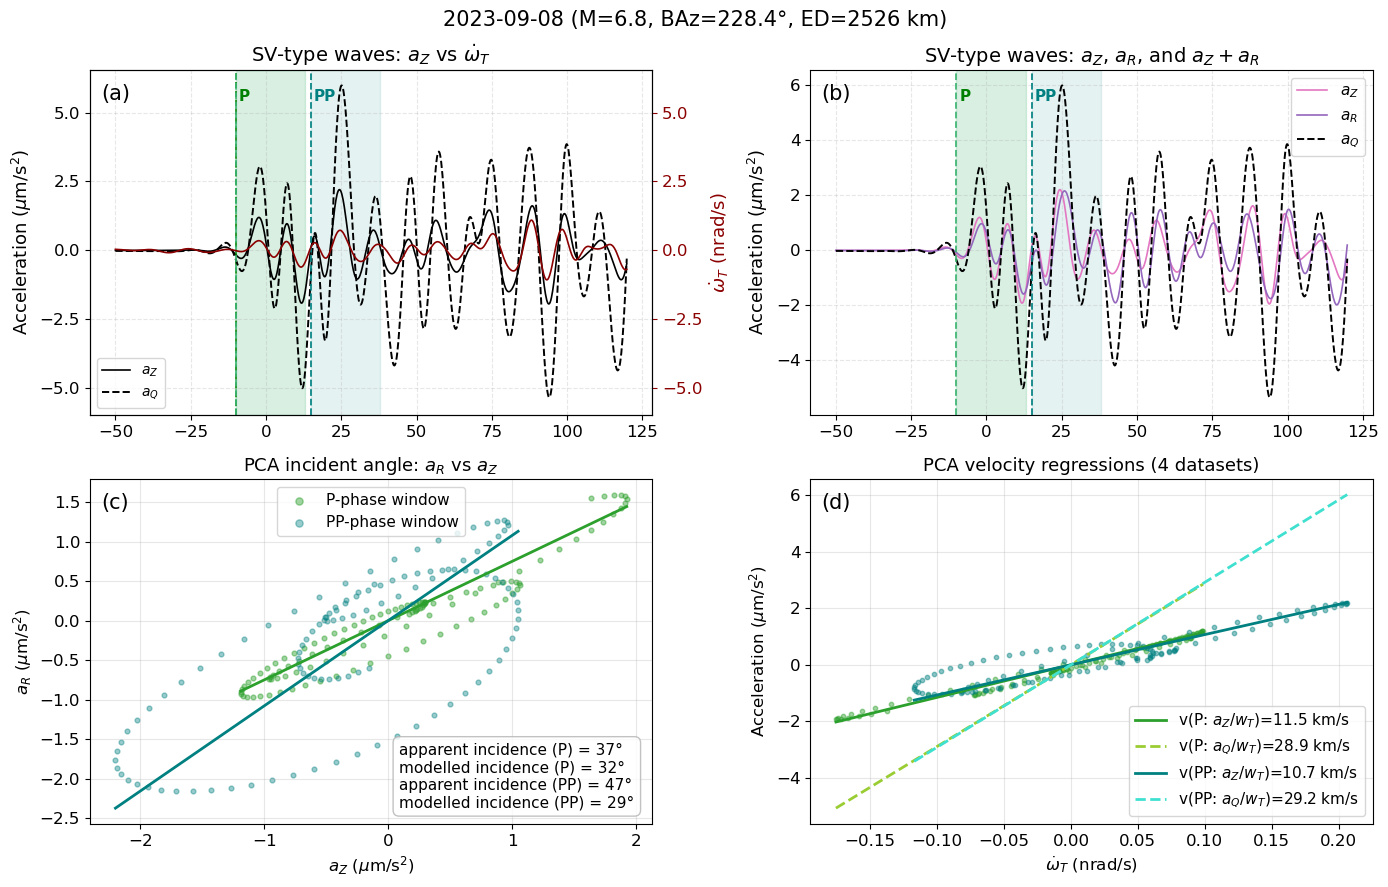

In [58]:
from matplotlib.ticker import MaxNLocator

fig2, axes2 = plt.subplots(2, 2, figsize=(14, 9), sharex=False)

########################################################
# upper-left (inlined from plot_overlay)
ax_ul = axes2[0, 0]
ax2_ul = ax_ul.twinx()

_tz = rel_time_seconds(tra_z)
_tr = rel_time_seconds(rot_t)
_w0 = p_arrival_s + p_window[0]
_w1 = p_arrival_s + p_window[1]
_mz = (_tz >= _w0) & (_tz <= _w1)
_mr = (_tr >= _w0) & (_tr <= _w1)

_xz = _tz[_mz] - p_arrival_s
_yz = tra_z.data[_mz] * 1e6
_xr = _tr[_mr] - p_arrival_s
_yr = rot_t.data[_mr] * 1e9 * 3.5

ax_ul.plot(_xz, _yz, color="black", lw=1.2)
ax2_ul.plot(_xr, _yr, color="darkred", lw=1.2)

_absmax = np.nanmax(np.abs(np.concatenate([_yz, _yr]))) if (_yz.size and _yr.size) else 1.0
if not np.isfinite(_absmax) or _absmax == 0:
    _absmax = 1.0
ax_ul.set_ylim(-_absmax, _absmax)
ax2_ul.set_ylim(-_absmax, _absmax)

# plot P-family arrivals with shift
for _ph, _arr in arrivals_map_P.items():
    if not np.isfinite(_arr):
        continue
    _xrel = (_arr + p_arrival_shift_s) - p_arrival_s
    if _xrel < p_window[0] or _xrel > p_window[1]:
        continue
    ax_ul.axvline(_xrel, color="green", ls="--", lw=1.2, alpha=0.95)

ax_ul.set_title("SV-type waves: $a_Z$ vs $\\dot{\\omega}_T$", fontsize=14)
ax_ul.set_ylabel("Acceleration ($\\mu$m/s$^2$)", color="black", fontsize=13)
ax2_ul.set_ylabel("$\\dot{\\omega}_T$ (nrad/s)", color="darkred", fontsize=13)
ax_ul.tick_params(axis="y", colors="black", labelsize=12)
ax2_ul.tick_params(axis="y", colors="darkred", labelsize=12)
ax_ul.tick_params(axis="x", labelsize=12)
ax_ul.grid(True, alpha=0.3, ls="--")

# add a_Q as dashed black line in upper-left
_tq = rel_time_seconds(a_P_Q_trace)
_w0q = p_arrival_s + p_window[0]
_w1q = p_arrival_s + p_window[1]
_mq = (_tq >= _w0q) & (_tq <= _w1q)
_xq = _tq[_mq] - p_arrival_s
_yq = a_P_Q_trace.data[_mq] * 1e6
axes2[0, 0].plot(_xq, _yq, color="black", lw=1.4, ls="--")

# legend for a_Z and a_Q in lower-left corner
h_az, = axes2[0, 0].plot([], [], color="black", lw=1.2, label="$a_Z$")
h_aq, = axes2[0, 0].plot([], [], color="black", lw=1.4, ls="--", label="$a_Q$")
axes2[0, 0].legend([h_az, h_aq], ["$a_Z$", "$a_Q$"], loc="lower left", fontsize=10)

# readjust y-limits
ylim = axes2[0, 0].get_ylim()
ymax = max(abs(ylim[0]), abs(ylim[1]), max(abs(_yq)))
axes2[0, 0].set_ylim(-ymax, ymax)
ax2_ul.set_ylim(-ymax, ymax)


########################################################
# upper-right: a_Z, a_R and stacked (a_Z+a_R)
ax_ur = axes2[0, 1]
# ax2_ur = ax_ur.twinx()

_tu = rel_time_seconds(tra_z)
_w0u = p_arrival_s + p_window[0]
_w1u = p_arrival_s + p_window[1]
_mu = (_tu >= _w0u) & (_tu <= _w1u)
_xu = _tu[_mu] - p_arrival_s

_yaz = tra_z_q.data[_mu] * 1e6
_yar = tra_r_q.data[_mu] * 1e6

ax_ur.plot(_xu, _yaz, color="tab:pink", lw=1.2, label="$a_Z$")
ax_ur.plot(_xu, _yar, color="tab:purple", lw=1.2, label="$a_R$")
ax_ur.plot(_xq, _yq, color="black", lw=1.4, ls="--", label="$a_Q$")

# keep rotation on twin axis for comparable scaling style
_tr = rel_time_seconds(rot_t)
_mr = (_tr >= _w0u) & (_tr <= _w1u)
_xr = _tr[_mr] - p_arrival_s
_yr = rot_t.data[_mr] * 1e9 * 3.5
# ax2_ur.plot(_xr, _yr, color="darkred", lw=1.0, alpha=0.7)

ax_ur.set_title("SV-type waves: $a_Z$, $a_R$, and $a_Z+a_R$", fontsize=14)
ax_ur.set_ylabel("Acceleration ($\mu$m/s$^2$)", color="black", fontsize=13)
# ax2_ur.set_ylabel("$\dot{\omega}_T$ (nrad/s)", color="darkred", fontsize=13)
ax_ur.tick_params(axis="y", colors="black", labelsize=12)
# ax2_ur.tick_params(axis="y", colors="darkred", labelsize=12)
ax_ur.tick_params(axis="x", labelsize=12)
ax_ur.grid(True, alpha=0.3, ls="--")
ax_ur.legend(loc="upper right", fontsize=11, markerscale=1.5)

# shaded windows in upper panels
reg_x0 = reg_w0 - p_arrival_s
reg_x1 = reg_w1 - p_arrival_s
reg2_x0 = reg2_w0 - p_arrival_s
reg2_x1 = reg2_w1 - p_arrival_s
for _ax in [axes2[0, 0], axes2[0, 1]]:
    _ax.axvspan(reg_x0, reg_x1, color="mediumseagreen", alpha=0.20, zorder=0)
    _ax.axvspan(reg2_x0, reg2_x1, color="teal", alpha=0.10, zorder=0)
    _ax.axvline(reg2_x0, color="teal", lw=1.3, ls="--", alpha=0.95)
    _ax.text(reg2_x0 + 1.0, 0.9, f"{second_phase_name}", transform=_ax.get_xaxis_transform(), alpha=1, zorder=3,
             color="teal", fontsize=11, fontweight="bold", va="bottom", ha="left")
    _ax.axvline(reg_x0, color="mediumseagreen", lw=1.3, ls="--", alpha=0.95)
    _ax.text(reg_x0 + 1.0, 0.9, f"P", transform=_ax.get_xaxis_transform(), alpha=1, zorder=3,
             color="green", fontsize=11, fontweight="bold", va="bottom", ha="left")

# sync y-limits in upper row
yl0 = axes2[0, 0].get_ylim()
yl1 = axes2[0, 1].get_ylim()
ymin_l, ymax_l = min(yl0[0], yl1[0]), max(yl0[1], yl1[1])
axes2[0, 0].set_ylim(ymin_l, ymax_l)
axes2[0, 1].set_ylim(ymin_l, ymax_l)
ax2_ul.set_ylim(ymin_l, ymax_l)

# align twin y-axis tick positions (upper-left)
_ul_ticks = MaxNLocator(nbins=6).tick_values(ymin_l, ymax_l)
_ul_ticks = _ul_ticks[(_ul_ticks >= ymin_l) & (_ul_ticks <= ymax_l)]
ax_ul.set_yticks(_ul_ticks)
ax2_ul.set_yticks(_ul_ticks)

# if ax2_ul is not None and ax2_ur is not None:
#     yr0 = ax2_ul.get_ylim()
#     yr1 = ax2_ur.get_ylim()
#     ymin_r, ymax_r = min(yr0[0], yr1[0]), max(yr0[1], yr1[1])
#     ax2_ul.set_ylim(ymin_r, ymax_r)
#     ax2_ur.set_ylim(ymin_r, ymax_r)


########################################################
# lower-left: incident regressions (plot-only)
ax = axes2[1, 0]

ax.scatter(xx_p, yy_p, s=12, color="tab:green", alpha=0.45, label="P-phase window")
if np.isfinite(slope_p_inc):
    xline = np.linspace(np.nanmin(xx_p), np.nanmax(xx_p), 100)
    ax.plot(xline, slope_p_inc * xline, color="tab:green", lw=2)

ax.scatter(xx_x, yy_x, s=12, color="teal", alpha=0.40, label=f"{second_phase_name}-phase window")
if np.isfinite(slope_x_inc):
    xline2 = np.linspace(np.nanmin(xx_x), np.nanmax(xx_x), 100)
    ax.plot(xline2, slope_x_inc * xline2, color="teal", lw=2)

ax.text(
    0.55, 0.04,
    f"apparent incidence (P) = {inc_P_deg:.0f}°\nmodelled incidence (P) = {expected_incident_deg:.0f}°\napparent incidence ({second_phase_name}) = {inc_X_deg:.0f}°\nmodelled incidence ({second_phase_name}) = {expected_incident_deg_PP:.0f}°",
    transform=ax.transAxes, va="bottom", ha="left", fontsize=11,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.7", alpha=0.8),
)

ax.set_title(f"{slope_method.upper()} incident angle: $a_R$ vs $a_Z$", fontsize=13)
ax.set_ylabel("$a_R$ ($\mu$m/s$^2$)", fontsize=12)
ax.set_xlabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="upper center", fontsize=11, markerscale=1.5)
ax.tick_params(axis='both', which='major', labelsize=12)


########################################################
# lower-right: velocity regressions (all 4 datasets; plot-only)
ax = axes2[1, 1]

c_p_az = "tab:green"
c_p_aQ = "yellowgreen"
c_s_az = "teal"
c_s_aQ = "turquoise"

if wt_p.size and azv_p.size:
    ax.scatter(wt_p, azv_p, s=10, color=c_p_az, alpha=0.45)
    if np.isfinite(v_p_az):
        xline = np.linspace(np.nanmin(wt_p), np.nanmax(wt_p), 100)
        ax.plot(xline, v_p_az * xline, color=c_p_az, lw=2, label=f"v(P: $a_Z$/$w_T$)"+f"={v_p_az:.1f} km/s")

if wt_p.size and aQv_p.size:
    # ax.scatter(wt_p, aQv_p, s=10, color=c_p_az, ls="--",alpha=0.45, label="P: $a_Q$ vs $\dot{\omega}_T$")
    if np.isfinite(v_p_aQ):
        xline = np.linspace(np.nanmin(wt_p), np.nanmax(wt_p), 100)
        ax.plot(xline, v_p_aQ * xline, color=c_p_aQ, lw=2, ls="--", label=f"v(P: $a_Q$/$w_T$)"+f"={v_p_aQ:.1f} km/s")

if wt_x.size and azv_x.size:
    label_s_az = second_phase_name + r": $a_Z$ vs $\dot{\omega}_T$"
    ax.scatter(wt_x, azv_x, s=10, color=c_s_az, alpha=0.45)
    if np.isfinite(v_x_az):
        xline2 = np.linspace(np.nanmin(wt_x), np.nanmax(wt_x), 100)
        ax.plot(xline2, v_x_az * xline2, color=c_s_az, lw=2, label=f"v({second_phase_name}"+": $a_Z$/$w_T$)"+f"={v_x_az:.1f} km/s")

if wt_x.size and aQv_x.size:
    label_s_aQ = second_phase_name + r": $a_Q$ vs $\dot{\omega}_T$"
    # ax.scatter(wt_x, aQv_x, s=10, color=c_s_az, ls="--", alpha=0.45, label=label_s_aQ)
    if np.isfinite(v_x_aQ):
        xline2 = np.linspace(np.nanmin(wt_x), np.nanmax(wt_x), 100)
        ax.plot(xline2, v_x_aQ * xline2, color=c_s_aQ, lw=2, ls="--", label=f"v({second_phase_name}"+": $a_Q$/$w_T$)"+f"={v_x_aQ:.1f} km/s")

ax.set_title(f"{slope_method.upper()} velocity regressions (4 datasets)", fontsize=13)
ax.set_xlabel("$\dot{\omega}_T$ (nrad/s)", fontsize=12)
ax.set_ylabel("Acceleration ($\mu$m/s$^2$)", fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right", fontsize=11)
ax.tick_params(axis='both', which='major', labelsize=12)

fig2.suptitle(
    f"{event_date} (M={config['magnitude']:.1f}, BAz={baz:.1f}°, ED={distance_km:.0f} km)",
    fontsize=15,
)


axes2[0, 0].text(0.02, 0.96, f"(a)", transform=axes2[0, 0].transAxes,
            va="top", ha="left", fontsize=15, color="black")
axes2[0, 1].text(0.02, 0.96, f"(b)", transform=axes2[0, 1].transAxes,
            va="top", ha="left", fontsize=15, color="black")
axes2[1, 0].text(0.02, 0.96, f"(c)", transform=axes2[1, 0].transAxes,
            va="top", ha="left", fontsize=15, color="black")
axes2[1, 1].text(0.02, 0.96, f"(d)", transform=axes2[1, 1].transAxes,
            va="top", ha="left", fontsize=15, color="black")

plt.tight_layout()
plt.show()

# fig.savefig(f"./output/figures/event/polarization_analysis.png", dpi=150, bbox_inches="tight")

## With S-wave Approach

S-phase arrivals and window

In [59]:
regression_window_s = 20

In [60]:
expected_incident_deg_S = np.nan
try:
    _model_inc_s = TauPyModel(model="prem")
    _s_inc = _model_inc_s.get_travel_times(
        source_depth_in_km=float(depth_km),
        distance_in_degree=float(distance_deg),
        phase_list=["S"],
    )
    if _s_inc:
        expected_incident_deg_S = getattr(_s_inc[0], "incident_angle", np.nan)
        print(f"expected_incident_deg_S: {expected_incident_deg_S:.1f}")
except Exception:
    pass

s_anchor_shifted = s_arrival_s + s_arrival_shift_s
reg_s_w0 = s_anchor_shifted
reg_s_w1 = s_anchor_shifted + regression_window_s

m_z_s = (t_z >= reg_s_w0) & (t_z <= reg_s_w1)
m_r_s = (t_r >= reg_s_w0) & (t_r <= reg_s_w1)
n_s = min(np.sum(m_z_s), np.sum(m_r_s))


expected_incident_deg_S: 28.0


S-wave incidence (Z over R due to polarization)

In [61]:

inc_S_deg = np.nan
inc_S_rad = np.nan
slope_s_inc = np.nan
xx_s = yy_s = np.array([])

if n_s > 3:
    xx_s = tra_r.data[m_z_s][:n_s] * 1e6
    yy_s = tra_z.data[m_r_s][:n_s] * 1e6
    slope_s_inc = _fit_slope(xx_s, yy_s, method=slope_method)
    if np.isfinite(slope_s_inc):
        inc_S_deg = abs(np.degrees(np.arctan(slope_s_inc)))
        inc_S_rad = np.deg2rad(inc_S_deg)
        print(f"incident_S_deg: {inc_S_deg:.1f}")
    else:
        print("Could not determine incident angle in S window")
else:
    print("Not enough samples in S window for incidence fit")


incident_S_deg: 6.5


S-wave velocity estimation

In [62]:

a_S_Q_trace = tra_z.copy()
# a_S_Q_trace.data = (tra_r_q.data / np.cos(inc_S_rad) + tra_z_q.data / np.sin(inc_S_rad)) / 2
a_S_Q_trace.data = tra_r.data + tra_z.data

arrivals_map_S = {k: v for k, v in arrivals_map.items() if k.upper() == "S"}

m_t_s = (t_t >= reg_s_w0) & (t_t <= reg_s_w1)
n2_s = min(np.sum(m_t_s), np.sum(m_z_s))

wt_s = azv_s = aQv_s = np.array([])
v_s_az = v_s_aQ = np.nan

if n2_s > 3 and np.isfinite(inc_S_rad):
    wt_s = rot_t.data[m_t_s][:n2_s] * 1e9
    azv_s = tra_z.data[m_z_s][:n2_s] * 1e6
    aQv_s = a_S_Q_trace.data[m_z_s][:n2_s] * 1e6
    v_s_az = _fit_slope(wt_s, azv_s, method=slope_method)
    v_s_aQ = _fit_slope(wt_s, aQv_s, method=slope_method)
    print(f"v(S: a_Z/w_T) = {v_s_az:.1f} km/s" if np.isfinite(v_s_az) else "v(S: a_Z/w_T) = nan")
    print(f"v(S: a_Q/w_T) = {v_s_aQ:.1f} km/s" if np.isfinite(v_s_aQ) else "v(S: a_Q/w_T) = nan")
else:
    print("Not enough samples in S window for velocity fit")


v(S: a_Z/w_T) = 6.0 km/s
v(S: a_Q/w_T) = 33.0 km/s


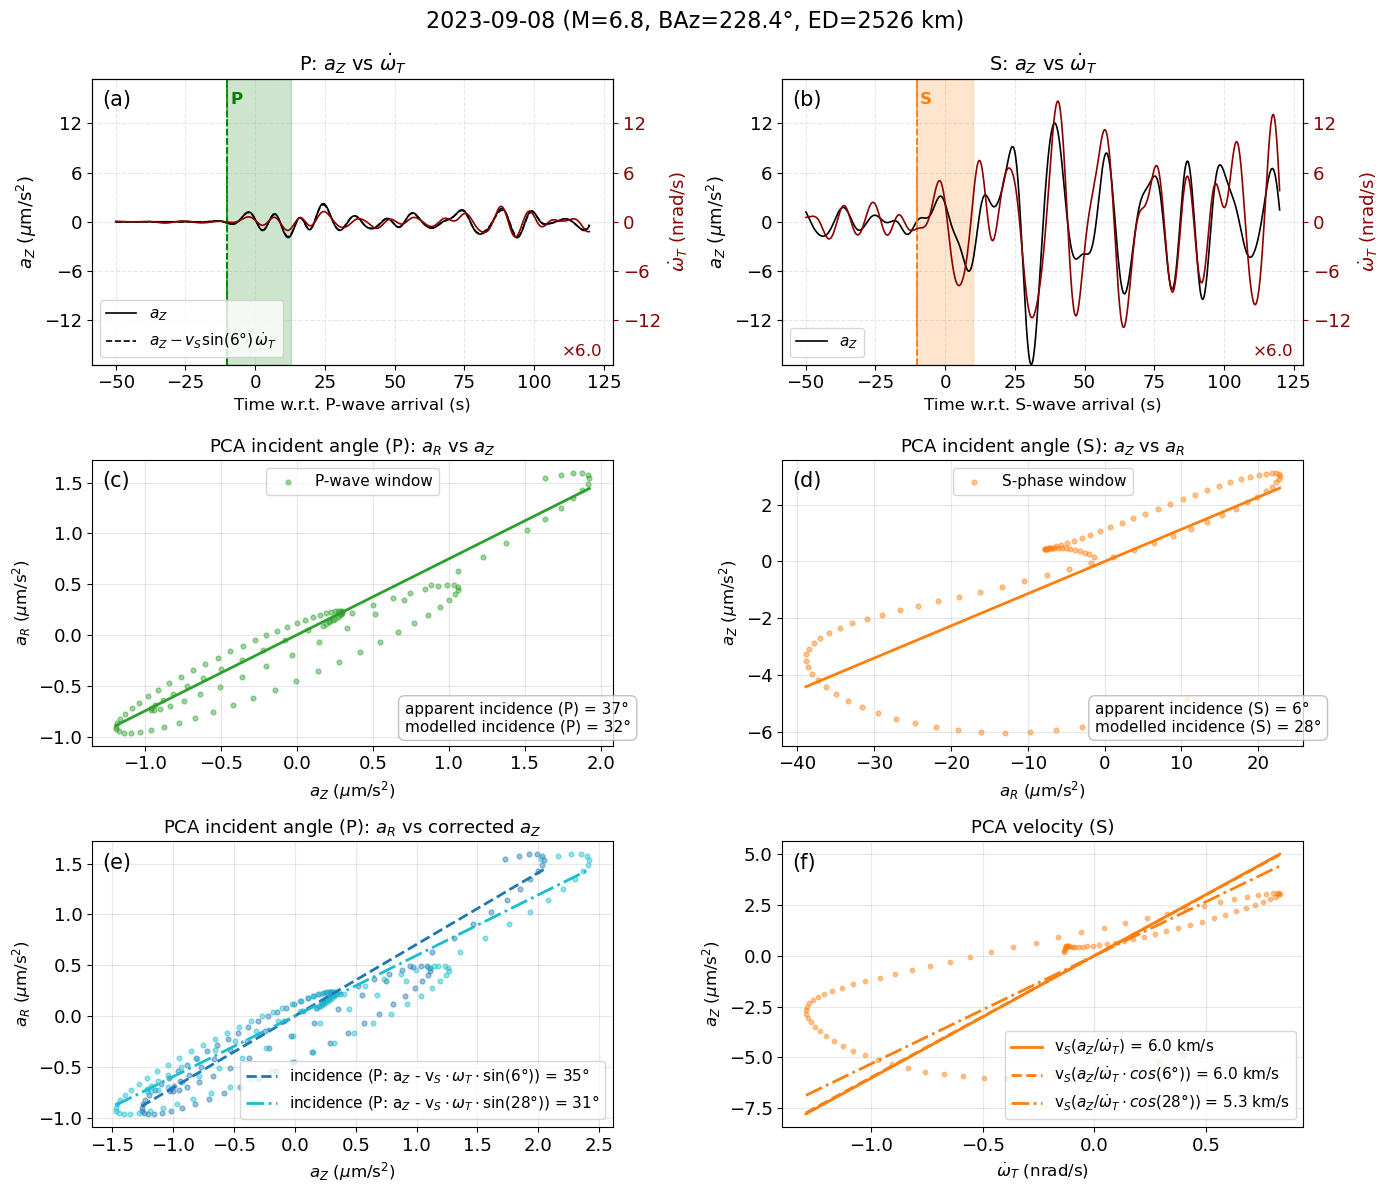

In [63]:
from matplotlib.ticker import MaxNLocator

fig3, axes3 = plt.subplots(3, 2, figsize=(14, 12), sharex=False)

reg_p_x0 = reg_w0 - p_arrival_s
reg_p_x1 = reg_w1 - p_arrival_s
reg_s_x0 = reg_s_w0 - s_arrival_s
reg_s_x1 = reg_s_w1 - s_arrival_s

rot_scale = v_s_az if np.isfinite(v_s_az) else 3.5

v_s_corr = v_s_az * np.sin(inc_S_rad)
v_s_corr_mod = v_s_az * np.sin(np.deg2rad(expected_incident_deg_S))

# P-window: corrected $a_Z$ samples for incidence (subtract $v_S\sin i_S\,\dot{\omega}_T$, two choices of $\sin i_S$)
wt_p_reg = rot_t.data[m_z_p][:n_p] * 1e9 if n_p > 3 else np.array([])
xx_p_corr = (xx_p - v_s_corr * wt_p_reg) if wt_p_reg.size else np.array([])
slope_p_inc_corr = np.nan
if xx_p_corr.size > 3 and yy_p.size > 3:
    slope_p_inc_corr = _fit_slope(xx_p_corr, yy_p, method=slope_method)
inc_P_deg_corr = abs(np.degrees(np.arctan(slope_p_inc_corr))) if np.isfinite(slope_p_inc_corr) else np.nan

xx_p_corr_mod = (xx_p - v_s_corr_mod * wt_p_reg) if wt_p_reg.size else np.array([])
slope_p_inc_corr_mod = np.nan
if xx_p_corr_mod.size > 3 and yy_p.size > 3:
    slope_p_inc_corr_mod = _fit_slope(xx_p_corr_mod, yy_p, method=slope_method)
inc_P_deg_corr_mod = abs(np.degrees(np.arctan(slope_p_inc_corr_mod))) if np.isfinite(slope_p_inc_corr_mod) else np.nan


def _waveform_overlay(ax, anchor_s, window, arrival_shift_s, arrivals_submap, phase_tag, reg_x0, reg_x1, phase_color="green", show_corrected=True):
    ax2 = ax.twinx()
    tz = rel_time_seconds(tra_z)
    tr = rel_time_seconds(rot_t)
    w0 = anchor_s + window[0]
    w1 = anchor_s + window[1]
    mz = (tz >= w0) & (tz <= w1)
    mr = (tr >= w0) & (tr <= w1)
    xz = tz[mz] - anchor_s
    yz = tra_z.data[mz] * 1e6
    wt_nrad = rot_t.data[mz] * 1e9
    xr = tr[mr] - anchor_s
    yr = rot_t.data[mr] * 1e9 * rot_scale

    ax.plot(xz, yz, color="black", lw=1.2, label="$a_Z$")
    if show_corrected and np.isfinite(v_s_corr):
        yz_corr = yz - v_s_corr * wt_nrad
        ax.plot(
            xz, yz_corr, color="black", lw=1.2, ls="--",
            label=rf"$a_Z - v_S \sin({inc_S_deg:.0f}°)\,\dot{{\omega}}_T$",
        )
    ax2.plot(xr, yr, color="darkred", lw=1.2)

    for _ph, _arr in arrivals_submap.items():
        if not np.isfinite(_arr):
            continue
        xrel = (_arr + arrival_shift_s) - anchor_s
        if xrel < window[0] or xrel > window[1]:
            continue
        ax.axvline(xrel, color=phase_color, ls="--", lw=1.2, alpha=0.95)

    series = [yz, yr]
    if show_corrected and np.isfinite(v_s_corr):
        series.append(yz_corr)
    absmax = np.nanmax(np.abs(np.concatenate(series))) if all(s.size for s in series) else 1.0
    if not np.isfinite(absmax) or absmax == 0:
        absmax = 1.0
    ax.set_ylim(-absmax, absmax)
    ax2.set_ylim(-absmax, absmax)

    ax.set_title(f"{phase_tag}: $a_Z$ vs $\\dot{{\\omega}}_T$", fontsize=14)
    ax.set_ylabel("$a_Z$ ($\\mu$m/s$^2$)", color="black", fontsize=13)
    ax2.set_ylabel("$\\dot{\\omega}_T$ (nrad/s)", color="darkred", fontsize=13)
    ax.tick_params(axis="y", colors="black", labelsize=13)
    ax2.tick_params(axis="y", colors="darkred", labelsize=13)
    ax.tick_params(axis="x", labelsize=13)
    ax.grid(True, alpha=0.3, ls="--")
    ax.legend(loc="lower left", fontsize=11)
    ax.axvspan(reg_x0, reg_x1, color=phase_color, alpha=0.20, zorder=0)
    ax.axvline(reg_x0, color=phase_color, lw=1.3, ls="--", alpha=0.95)
    ax.text(
        reg_x0 + 1.0, 0.9, phase_tag,
        transform=ax.get_xaxis_transform(), color=phase_color,
        fontsize=12, fontweight="bold", va="bottom", ha="left", zorder=3,
    )
    ax.text(
        0.98, 0.02, f"$\\times{{{rot_scale:.1f}}}$",
        transform=ax.transAxes, color="darkred", fontsize=12,
        ha="right", va="bottom", zorder=4,
    )
    return ax2


# row 0: overlay traces (P and S)
ax2_p = _waveform_overlay(
    axes3[0, 0], p_arrival_s, p_window, p_arrival_shift_s,
    arrivals_map_P, "P", reg_p_x0, reg_p_x1,
)
axes3[0, 0].set_xlabel("Time w.r.t. P-wave arrival (s)", fontsize=12)

ax2_s = _waveform_overlay(
    axes3[0, 1], s_arrival_s, s_window, s_arrival_shift_s,
    arrivals_map_S, "S", reg_s_x0, reg_s_x1, phase_color="tab:orange", show_corrected=False,
)
axes3[0, 1].set_xlabel("Time w.r.t. S-wave arrival (s)", fontsize=12)

# sync y-limits on overlay row
yl = [axes3[0, c].get_ylim() for c in (0, 1)]
ymin = min(y[0] for y in yl)
ymax = max(y[1] for y in yl)
axes3[0, 0].set_ylim(ymin, ymax)
axes3[0, 1].set_ylim(ymin, ymax)
ax2_p.set_ylim(ymin, ymax)
ax2_s.set_ylim(ymin, ymax)
ticks = MaxNLocator(nbins=6).tick_values(ymin, ymax)
ticks = ticks[(ticks >= ymin) & (ticks <= ymax)]
axes3[0, 0].set_yticks(ticks)
ax2_p.set_yticks(ticks)
axes3[0, 1].set_yticks(ticks)
ax2_s.set_yticks(ticks)

# row 1: incidence regressions
ax_p_inc = axes3[1, 0]
ax_p_inc.scatter(xx_p, yy_p, s=12, color="tab:green", alpha=0.45, label="P-wave window")
if np.isfinite(slope_p_inc):
    xline = np.linspace(np.nanmin(xx_p), np.nanmax(xx_p), 100)
    ax_p_inc.plot(xline, slope_p_inc * xline, color="tab:green", lw=2)
ax_p_inc.text(
    0.6, 0.04,
    f"apparent incidence (P) = {inc_P_deg:.0f}°\nmodelled incidence (P) = {expected_incident_deg:.0f}°",
    transform=ax_p_inc.transAxes, va="bottom", ha="left", fontsize=11,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.7", alpha=0.8),
)
ax_p_inc.set_title(f"{slope_method.upper()} incident angle (P): $a_R$ vs $a_Z$", fontsize=13)
ax_p_inc.set_ylabel("$a_R$ ($\mu$m/s$^2$)", fontsize=12)
ax_p_inc.set_xlabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax_p_inc.grid(True, alpha=0.3)
ax_p_inc.legend(loc="upper center", fontsize=11)
ax_p_inc.tick_params(axis="both", labelsize=13)

ax_s_inc = axes3[1, 1]
if xx_s.size:
    ax_s_inc.scatter(xx_s, yy_s, s=12, color="tab:orange", alpha=0.45, label="S-phase window")
if np.isfinite(slope_s_inc):
    xline_s = np.linspace(np.nanmin(xx_s), np.nanmax(xx_s), 100)
    ax_s_inc.plot(xline_s, slope_s_inc * xline_s, color="tab:orange", lw=2)
ax_s_inc.text(
    0.6, 0.04,
    f"apparent incidence (S) = {inc_S_deg:.0f}°\nmodelled incidence (S) = {expected_incident_deg_S:.0f}°",
    transform=ax_s_inc.transAxes, va="bottom", ha="left", fontsize=11,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.7", alpha=0.8),
)
ax_s_inc.set_title(f"{slope_method.upper()} incident angle (S): $a_Z$ vs $a_R$", fontsize=13)
ax_s_inc.set_ylabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax_s_inc.set_xlabel("$a_R$ ($\mu$m/s$^2$)", fontsize=12)
ax_s_inc.grid(True, alpha=0.3)
ax_s_inc.legend(loc="upper center", fontsize=11)
ax_s_inc.tick_params(axis="both", labelsize=13)

# row 2: corrected P incidence (left); S velocity (right)
ax_p_corr = axes3[2, 0]
lbl1 = f"incidence (P: a$_Z$ - v$_S \cdot \\omega_T \cdot \\sin({inc_S_deg:.0f}°)$) = {inc_P_deg_corr:.0f}°"
lbl2 = f"incidence (P: a$_Z$ - v$_S \cdot \\omega_T \cdot \\sin({expected_incident_deg_S:.0f}°)$) = {inc_P_deg_corr_mod:.0f}°"
if xx_p_corr.size:
    ax_p_corr.scatter(xx_p_corr, yy_p, s=12, color="tab:blue", alpha=0.45)
if np.isfinite(slope_p_inc_corr):
    xline_c = np.linspace(np.nanmin(xx_p_corr), np.nanmax(xx_p_corr), 100)
    ax_p_corr.plot(xline_c, slope_p_inc_corr * xline_c, color="tab:blue", lw=2, ls="--", label=lbl1)
if xx_p_corr_mod.size:
    ax_p_corr.scatter(xx_p_corr_mod, yy_p, s=12, color="tab:cyan", alpha=0.45)
if np.isfinite(slope_p_inc_corr_mod):
    xline_m = np.linspace(np.nanmin(xx_p_corr_mod), np.nanmax(xx_p_corr_mod), 100)
    ax_p_corr.plot(xline_m, slope_p_inc_corr_mod * xline_m, color="tab:cyan", lw=2, ls="-.", label=lbl2)
ax_p_corr.set_title(
    f"{slope_method.upper()} incident angle (P): $a_R$ vs corrected $a_Z$",
    fontsize=13,
)
ax_p_corr.set_ylabel("$a_R$ ($\mu$m/s$^2$)", fontsize=12)
ax_p_corr.set_xlabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax_p_corr.grid(True, alpha=0.3)
ax_p_corr.legend(loc="lower right", fontsize=11, ncol=1)
ax_p_corr.tick_params(axis="both", labelsize=13)

ax_s_vel = axes3[2, 1]
if wt_s.size and azv_s.size:
    ax_s_vel.scatter(wt_s, azv_s, s=10, color="tab:orange", alpha=0.45)
    if np.isfinite(v_s_az):
        xline_s = np.linspace(np.nanmin(wt_s), np.nanmax(wt_s), 100)
        ax_s_vel.plot(xline_s, v_s_az * xline_s, color="tab:orange", lw=2, label=f"v$_S$($a_Z$/$\\dot{{\\omega}}_T$) = {v_s_az:.1f} km/s")

        v_s_az_adj = v_s_az * np.cos(inc_S_rad)
        ax_s_vel.plot(xline_s, v_s_az_adj * xline_s, color="tab:orange", lw=2, ls="--", label=f"v$_S$($a_Z$/$\\dot{{\\omega}}_T \cdot cos$({inc_S_deg:.0f}°)) = {v_s_az_adj:.1f} km/s")
        v_s_az_mod = v_s_az * np.cos(np.deg2rad(expected_incident_deg_S))
        ax_s_vel.plot(xline_s, v_s_az_mod * xline_s, color="tab:orange", lw=2, ls="-.", label=f"v$_S$($a_Z$/$\\dot{{\\omega}}_T \cdot cos$({expected_incident_deg_S:.0f}°)) = {v_s_az_mod:.1f} km/s")

ax_s_vel.set_title(f"{slope_method.upper()} velocity (S)", fontsize=13)
ax_s_vel.set_xlabel("$\\dot{\\omega}_T$ (nrad/s)", fontsize=12)
ax_s_vel.set_ylabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax_s_vel.grid(True, alpha=0.3)
ax_s_vel.legend(loc="lower right", fontsize=11)
ax_s_vel.tick_params(axis="both", labelsize=13)

fig3.suptitle(
    f"{event_date} (M={config['magnitude']:.1f}, BAz={baz:.1f}°, ED={distance_km:.0f} km)",
    y=0.99,
    fontsize=16,
)

labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]
for idx, (r, c) in enumerate([(0, 0), (0, 1), (1, 0), (1, 1), (2, 0), (2, 1)]):
    axes3[r, c].text(
        0.02, 0.96, labels[idx], transform=axes3[r, c].transAxes,
        va="top", ha="left", fontsize=15, color="black",
    )

plt.tight_layout()
plt.show()

fig3.savefig(F"./output/figures/event/event_{event_date}polarization_analysis_P_S.png", dpi=150, bbox_inches="tight")


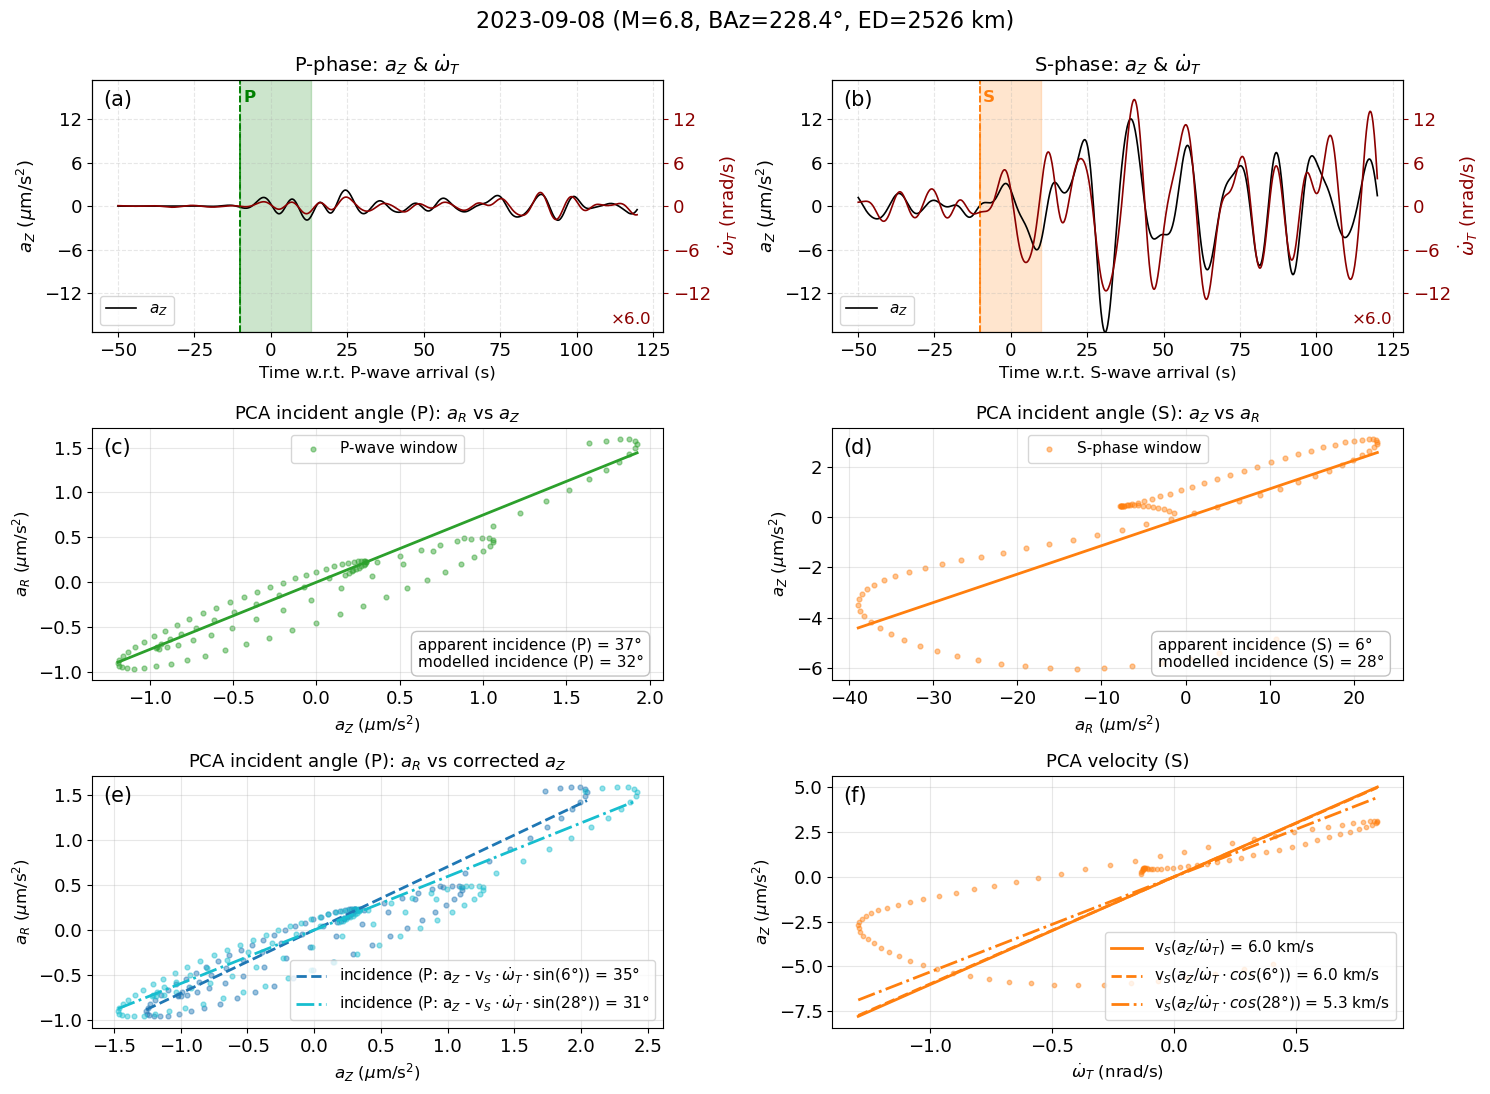

In [66]:
from matplotlib.ticker import MaxNLocator

fig3, axes3 = plt.subplots(3, 2, figsize=(15, 11), sharex=False)

reg_p_x0 = reg_w0 - p_arrival_s
reg_p_x1 = reg_w1 - p_arrival_s
reg_s_x0 = reg_s_w0 - s_arrival_s
reg_s_x1 = reg_s_w1 - s_arrival_s

rot_scale = v_s_az if np.isfinite(v_s_az) else 3.5

v_s_corr = v_s_az * np.sin(inc_S_rad)
v_s_corr_mod = v_s_az * np.sin(np.deg2rad(expected_incident_deg_S))

# P-window: corrected $a_Z$ samples for incidence (subtract $v_S\sin i_S\,\dot{\omega}_T$, two choices of $\sin i_S$)
wt_p_reg = rot_t.data[m_z_p][:n_p] * 1e9 if n_p > 3 else np.array([])
xx_p_corr = (xx_p - v_s_corr * wt_p_reg) if wt_p_reg.size else np.array([])
slope_p_inc_corr = np.nan
if xx_p_corr.size > 3 and yy_p.size > 3:
    slope_p_inc_corr = _fit_slope(xx_p_corr, yy_p, method=slope_method)
inc_P_deg_corr = abs(np.degrees(np.arctan(slope_p_inc_corr))) if np.isfinite(slope_p_inc_corr) else np.nan

xx_p_corr_mod = (xx_p - v_s_corr_mod * wt_p_reg) if wt_p_reg.size else np.array([])
slope_p_inc_corr_mod = np.nan
if xx_p_corr_mod.size > 3 and yy_p.size > 3:
    slope_p_inc_corr_mod = _fit_slope(xx_p_corr_mod, yy_p, method=slope_method)
inc_P_deg_corr_mod = abs(np.degrees(np.arctan(slope_p_inc_corr_mod))) if np.isfinite(slope_p_inc_corr_mod) else np.nan


def _waveform_overlay(ax, anchor_s, window, arrival_shift_s, arrivals_submap, phase_tag, reg_x0, reg_x1, phase_color="green", show_corrected=True):
    ax2 = ax.twinx()
    tz = rel_time_seconds(tra_z)
    tr = rel_time_seconds(rot_t)
    w0 = anchor_s + window[0]
    w1 = anchor_s + window[1]
    mz = (tz >= w0) & (tz <= w1)
    mr = (tr >= w0) & (tr <= w1)
    xz = tz[mz] - anchor_s
    yz = tra_z.data[mz] * 1e6
    wt_nrad = rot_t.data[mz] * 1e9
    xr = tr[mr] - anchor_s
    yr = rot_t.data[mr] * 1e9 * rot_scale

    ax.plot(xz, yz, color="black", lw=1.2, label="$a_Z$")
    if show_corrected and np.isfinite(v_s_corr):
        yz_corr = yz - v_s_corr * wt_nrad
        ax.plot(
            xz, yz_corr, color="black", lw=1.2, ls="--",
            label=rf"$a_Z - v_S \sin({inc_S_deg:.0f}°)\,\dot{{\omega}}_T$",
        )
    ax2.plot(xr, yr, color="darkred", lw=1.2)

    for _ph, _arr in arrivals_submap.items():
        if not np.isfinite(_arr):
            continue
        xrel = (_arr + arrival_shift_s) - anchor_s
        if xrel < window[0] or xrel > window[1]:
            continue
        ax.axvline(xrel, color=phase_color, ls="--", lw=1.2, alpha=0.95)

    series = [yz, yr]
    if show_corrected and np.isfinite(v_s_corr):
        series.append(yz_corr)
    absmax = np.nanmax(np.abs(np.concatenate(series))) if all(s.size for s in series) else 1.0
    if not np.isfinite(absmax) or absmax == 0:
        absmax = 1.0
    ax.set_ylim(-absmax, absmax)
    ax2.set_ylim(-absmax, absmax)

    ax.set_title(f"{phase_tag}-phase: $a_Z$ & $\\dot{{\\omega}}_T$", fontsize=14)
    ax.set_ylabel("$a_Z$ ($\\mu$m/s$^2$)", color="black", fontsize=13)
    ax2.set_ylabel("$\\dot{\\omega}_T$ (nrad/s)", color="darkred", fontsize=13)
    ax.tick_params(axis="y", colors="black", labelsize=13)
    ax2.tick_params(axis="y", colors="darkred", labelsize=13)
    ax.tick_params(axis="x", labelsize=13)
    ax.grid(True, alpha=0.3, ls="--")
    ax.legend(loc="lower left", fontsize=11)
    ax.axvspan(reg_x0, reg_x1, color=phase_color, alpha=0.20, zorder=0)
    ax.axvline(reg_x0, color=phase_color, lw=1.3, ls="--", alpha=0.95)
    ax.text(
        reg_x0 + 1.0, 0.9, phase_tag,
        transform=ax.get_xaxis_transform(), color=phase_color,
        fontsize=12, fontweight="bold", va="bottom", ha="left", zorder=3,
    )
    ax.text(
        0.98, 0.02, f"$\\times{{{rot_scale:.1f}}}$",
        transform=ax.transAxes, color="darkred", fontsize=12,
        ha="right", va="bottom", zorder=4,
    )
    return ax2


# row 0: overlay traces (P and S)
ax2_p = _waveform_overlay(
    axes3[0, 0], p_arrival_s, p_window, p_arrival_shift_s,
    arrivals_map_P, "P", reg_p_x0, reg_p_x1, show_corrected=False,
)
axes3[0, 0].set_xlabel("Time w.r.t. P-wave arrival (s)", fontsize=12)

ax2_s = _waveform_overlay(
    axes3[0, 1], s_arrival_s, s_window, s_arrival_shift_s,
    arrivals_map_S, "S", reg_s_x0, reg_s_x1, phase_color="tab:orange", show_corrected=False,
)
axes3[0, 1].set_xlabel("Time w.r.t. S-wave arrival (s)", fontsize=12)

# sync y-limits on overlay row
yl = [axes3[0, c].get_ylim() for c in (0, 1)]
ymin = min(y[0] for y in yl)
ymax = max(y[1] for y in yl)
axes3[0, 0].set_ylim(ymin, ymax)
axes3[0, 1].set_ylim(ymin, ymax)
ax2_p.set_ylim(ymin, ymax)
ax2_s.set_ylim(ymin, ymax)
ticks = MaxNLocator(nbins=6).tick_values(ymin, ymax)
ticks = ticks[(ticks >= ymin) & (ticks <= ymax)]
axes3[0, 0].set_yticks(ticks)
ax2_p.set_yticks(ticks)
axes3[0, 1].set_yticks(ticks)
ax2_s.set_yticks(ticks)

# row 1: incidence regressions
ax_p_inc = axes3[1, 0]
ax_p_inc.scatter(xx_p, yy_p, s=12, color="tab:green", alpha=0.45, label="P-wave window")
if np.isfinite(slope_p_inc):
    xline = np.linspace(np.nanmin(xx_p), np.nanmax(xx_p), 100)
    ax_p_inc.plot(xline, slope_p_inc * xline, color="tab:green", lw=2)
ax_p_inc.text(
    0.57, 0.04,
    f"apparent incidence (P) = {inc_P_deg:.0f}°\nmodelled incidence (P) = {expected_incident_deg:.0f}°",
    transform=ax_p_inc.transAxes, va="bottom", ha="left", fontsize=11,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.7", alpha=0.8),
)
ax_p_inc.set_title(f"{slope_method.upper()} incident angle (P): $a_R$ vs $a_Z$", fontsize=13)
ax_p_inc.set_ylabel("$a_R$ ($\mu$m/s$^2$)", fontsize=12)
ax_p_inc.set_xlabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax_p_inc.grid(True, alpha=0.3)
ax_p_inc.legend(loc="upper center", fontsize=11)
ax_p_inc.tick_params(axis="both", labelsize=13)

ax_s_inc = axes3[1, 1]
if xx_s.size:
    ax_s_inc.scatter(xx_s, yy_s, s=12, color="tab:orange", alpha=0.45, label="S-phase window")
if np.isfinite(slope_s_inc):
    xline_s = np.linspace(np.nanmin(xx_s), np.nanmax(xx_s), 100)
    ax_s_inc.plot(xline_s, slope_s_inc * xline_s, color="tab:orange", lw=2)
ax_s_inc.text(
    0.57, 0.04,
    f"apparent incidence (S) = {inc_S_deg:.0f}°\nmodelled incidence (S) = {expected_incident_deg_S:.0f}°",
    transform=ax_s_inc.transAxes, va="bottom", ha="left", fontsize=11,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.7", alpha=0.8),
)
ax_s_inc.set_title(f"{slope_method.upper()} incident angle (S): $a_Z$ vs $a_R$", fontsize=13)
ax_s_inc.set_ylabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax_s_inc.set_xlabel("$a_R$ ($\mu$m/s$^2$)", fontsize=12)
ax_s_inc.grid(True, alpha=0.3)
ax_s_inc.legend(loc="upper center", fontsize=11)
ax_s_inc.tick_params(axis="both", labelsize=13)

# row 2: corrected P incidence (left); S velocity (right)
ax_p_corr = axes3[2, 0]
lbl1 = f"incidence (P: a$_Z$ - v$_S \cdot \dot\omega_T \cdot \\sin({inc_S_deg:.0f}°)$) = {inc_P_deg_corr:.0f}°"
lbl2 = f"incidence (P: a$_Z$ - v$_S \cdot \\dot\omega_T \cdot \\sin({expected_incident_deg_S:.0f}°)$) = {inc_P_deg_corr_mod:.0f}°"
if xx_p_corr.size:
    ax_p_corr.scatter(xx_p_corr, yy_p, s=12, color="tab:blue", alpha=0.45)
if np.isfinite(slope_p_inc_corr):
    xline_c = np.linspace(np.nanmin(xx_p_corr), np.nanmax(xx_p_corr), 100)
    ax_p_corr.plot(xline_c, slope_p_inc_corr * xline_c, color="tab:blue", lw=2, ls="--", label=lbl1)
if xx_p_corr_mod.size:
    ax_p_corr.scatter(xx_p_corr_mod, yy_p, s=12, color="tab:cyan", alpha=0.45)
if np.isfinite(slope_p_inc_corr_mod):
    xline_m = np.linspace(np.nanmin(xx_p_corr_mod), np.nanmax(xx_p_corr_mod), 100)
    ax_p_corr.plot(xline_m, slope_p_inc_corr_mod * xline_m, color="tab:cyan", lw=2, ls="-.", label=lbl2)
ax_p_corr.set_title(
    f"{slope_method.upper()} incident angle (P): $a_R$ vs corrected $a_Z$",
    fontsize=13,
)
ax_p_corr.set_ylabel("$a_R$ ($\mu$m/s$^2$)", fontsize=12)
ax_p_corr.set_xlabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax_p_corr.grid(True, alpha=0.3)
ax_p_corr.legend(loc="lower right", fontsize=11, ncol=1)
ax_p_corr.tick_params(axis="both", labelsize=13)

ax_s_vel = axes3[2, 1]
if wt_s.size and azv_s.size:
    ax_s_vel.scatter(wt_s, azv_s, s=10, color="tab:orange", alpha=0.45)
    if np.isfinite(v_s_az):
        xline_s = np.linspace(np.nanmin(wt_s), np.nanmax(wt_s), 100)
        ax_s_vel.plot(xline_s, v_s_az * xline_s, color="tab:orange", lw=2, label=f"v$_S$($a_Z$/$\\dot{{\\omega}}_T$) = {v_s_az:.1f} km/s")

        v_s_az_adj = v_s_az * np.cos(inc_S_rad)
        ax_s_vel.plot(xline_s, v_s_az_adj * xline_s, color="tab:orange", lw=2, ls="--", label=f"v$_S$($a_Z$/$\\dot{{\\omega}}_T \cdot cos$({inc_S_deg:.0f}°)) = {v_s_az_adj:.1f} km/s")
        v_s_az_mod = v_s_az * np.cos(np.deg2rad(expected_incident_deg_S))
        ax_s_vel.plot(xline_s, v_s_az_mod * xline_s, color="tab:orange", lw=2, ls="-.", label=f"v$_S$($a_Z$/$\\dot{{\\omega}}_T \cdot cos$({expected_incident_deg_S:.0f}°)) = {v_s_az_mod:.1f} km/s")

ax_s_vel.set_title(f"{slope_method.upper()} velocity (S)", fontsize=13)
ax_s_vel.set_xlabel("$\\dot{\\omega}_T$ (nrad/s)", fontsize=12)
ax_s_vel.set_ylabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax_s_vel.grid(True, alpha=0.3)
ax_s_vel.legend(loc="lower right", fontsize=11)
ax_s_vel.tick_params(axis="both", labelsize=13)

fig3.suptitle(
    f"{event_date} (M={config['magnitude']:.1f}, BAz={baz:.1f}°, ED={distance_km:.0f} km)",
    y=0.99,
    fontsize=16,
)

labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]
for idx, (r, c) in enumerate([(0, 0), (0, 1), (1, 0), (1, 1), (2, 0), (2, 1)]):
    axes3[r, c].text(
        0.02, 0.96, labels[idx], transform=axes3[r, c].transAxes,
        va="top", ha="left", fontsize=15, color="black",
    )

plt.tight_layout()
plt.show()

fig3.savefig(F"./output/figures/event/event_{event_date}polarization_analysis_P_S.png", dpi=200, bbox_inches="tight")


## OLD 

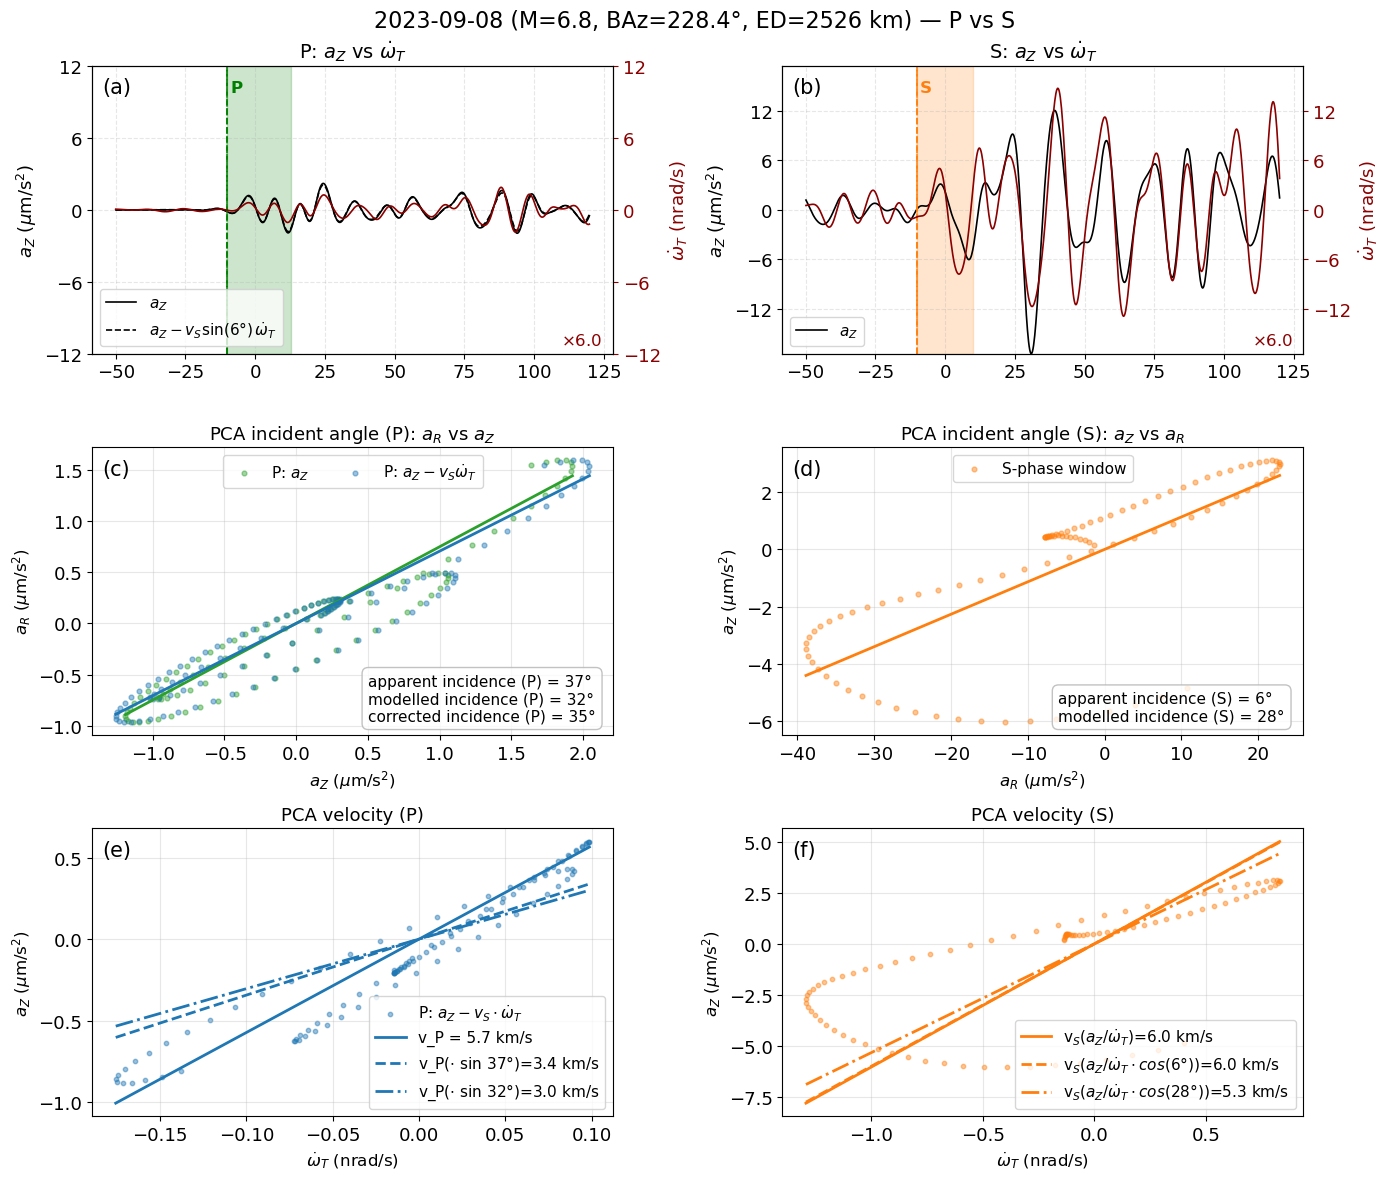

In [42]:
from matplotlib.ticker import MaxNLocator

fig3, axes3 = plt.subplots(3, 2, figsize=(14, 12), sharex=False)

reg_p_x0 = reg_w0 - p_arrival_s
reg_p_x1 = reg_w1 - p_arrival_s
reg_s_x0 = reg_s_w0 - s_arrival_s
reg_s_x1 = reg_s_w1 - s_arrival_s

rot_scale = v_s_az if np.isfinite(v_s_az) else 3.5

v_s_corr = v_s_az * np.sin(inc_S_rad)

# P-window corrected vertical acceleration: a_Z - v_S sin(i_S) dot{omega}_T
wt_p_reg = rot_t.data[m_z_p][:n_p] * 1e9 if n_p > 3 else np.array([])
xx_p_corr = (xx_p - v_s_corr * wt_p_reg) if wt_p_reg.size else np.array([])
slope_p_inc_corr = np.nan
if xx_p_corr.size > 3 and yy_p.size > 3:
    slope_p_inc_corr = _fit_slope(xx_p_corr, yy_p, method=slope_method)
inc_P_deg_corr = abs(np.degrees(np.arctan(slope_p_inc_corr)))

azv_p_corr = (azv_p - rot_scale * wt_p) if wt_p.size else np.array([])
v_p_az_corr = np.nan
if azv_p_corr.size > 3 and wt_p.size > 3:
    v_p_az_corr = _fit_slope(wt_p, azv_p_corr, method=slope_method)


def _waveform_overlay(ax, anchor_s, window, arrival_shift_s, arrivals_submap, phase_tag, reg_x0, reg_x1, phase_color="green", show_corrected=True):
    ax2 = ax.twinx()
    tz = rel_time_seconds(tra_z)
    tr = rel_time_seconds(rot_t)
    w0 = anchor_s + window[0]
    w1 = anchor_s + window[1]
    mz = (tz >= w0) & (tz <= w1)
    mr = (tr >= w0) & (tr <= w1)
    xz = tz[mz] - anchor_s
    yz = tra_z.data[mz] * 1e6
    wt_nrad = rot_t.data[mz] * 1e9
    xr = tr[mr] - anchor_s
    yr = rot_t.data[mr] * 1e9 * rot_scale

    ax.plot(xz, yz, color="black", lw=1.2, label="$a_Z$")
    if show_corrected and np.isfinite(v_s_corr):
        yz_corr = yz - v_s_corr * wt_nrad
        ax.plot(
            xz, yz_corr, color="black", lw=1.2, ls="--",
            label=rf"$a_Z - v_S \sin({inc_S_deg:.0f}°)\,\dot{{\omega}}_T$",
        )
    ax2.plot(xr, yr, color="darkred", lw=1.2)

    for _ph, _arr in arrivals_submap.items():
        if not np.isfinite(_arr):
            continue
        xrel = (_arr + arrival_shift_s) - anchor_s
        if xrel < window[0] or xrel > window[1]:
            continue
        ax.axvline(xrel, color=phase_color, ls="--", lw=1.2, alpha=0.95)

    series = [yz, yr]
    if show_corrected and np.isfinite(v_s_corr):
        series.append(yz_corr)
    absmax = np.nanmax(np.abs(np.concatenate(series))) if all(s.size for s in series) else 1.0
    if not np.isfinite(absmax) or absmax == 0:
        absmax = 1.0
    ax.set_ylim(-absmax, absmax)
    ax2.set_ylim(-absmax, absmax)

    ax.set_title(f"{phase_tag}: $a_Z$ vs $\\dot{{\\omega}}_T$", fontsize=14)
    ax.set_ylabel("$a_Z$ ($\\mu$m/s$^2$)", color="black", fontsize=13)
    ax2.set_ylabel("$\\dot{\\omega}_T$ (nrad/s)", color="darkred", fontsize=13)
    ax.tick_params(axis="y", colors="black", labelsize=13)
    ax2.tick_params(axis="y", colors="darkred", labelsize=13)
    ax.tick_params(axis="x", labelsize=13)
    ax.grid(True, alpha=0.3, ls="--")
    ax.legend(loc="lower left", fontsize=11)
    ax.axvspan(reg_x0, reg_x1, color=phase_color, alpha=0.20, zorder=0)
    ax.axvline(reg_x0, color=phase_color, lw=1.3, ls="--", alpha=0.95)
    ax.text(
        reg_x0 + 1.0, 0.9, phase_tag,
        transform=ax.get_xaxis_transform(), color=phase_color,
        fontsize=12, fontweight="bold", va="bottom", ha="left", zorder=3,
    )
    ax.text(
        0.98, 0.02, f"$\\times{{{rot_scale:.1f}}}$",
        transform=ax.transAxes, color="darkred", fontsize=12,
        ha="right", va="bottom", zorder=4,
    )
    return ax2


# row 0: overlay traces (P and S)
ax2_p = _waveform_overlay(
    axes3[0, 0], p_arrival_s, p_window, p_arrival_shift_s,
    arrivals_map_P, "P", reg_p_x0, reg_p_x1,
)
ax2_s = _waveform_overlay(
    axes3[0, 1], s_arrival_s, s_window, s_arrival_shift_s,
    arrivals_map_S, "S", reg_s_x0, reg_s_x1, phase_color="tab:orange", show_corrected=False,
)

# sync y-limits on overlay row
yl = [axes3[0, c].get_ylim() for c in (0, 1)]
ymin = min(y[0] for y in yl)
ymax = max(y[1] for y in yl)
# axes3[0, 0].set_ylim(ymin, ymax)
# axes3[0, 1].set_ylim(ymin, ymax)
# ax2_p.set_ylim(ymin, ymax)
# ax2_s.set_ylim(ymin, ymax)
ticks = MaxNLocator(nbins=6).tick_values(ymin, ymax)
ticks = ticks[(ticks >= ymin) & (ticks <= ymax)]
axes3[0, 0].set_yticks(ticks)
ax2_p.set_yticks(ticks)
axes3[0, 1].set_yticks(ticks)
ax2_s.set_yticks(ticks)

# row 1: incidence regressions
ax_p_inc = axes3[1, 0]
ax_p_inc.scatter(xx_p, yy_p, s=12, color="tab:green", alpha=0.45, label="P: $a_Z$")
if np.isfinite(slope_p_inc):
    xline = np.linspace(np.nanmin(xx_p), np.nanmax(xx_p), 100)
    ax_p_inc.plot(xline, slope_p_inc * xline, color="tab:green", lw=2)
if xx_p_corr.size:
    ax_p_inc.scatter(xx_p_corr, yy_p, s=12, color="tab:blue", alpha=0.45,
                     label=r"P: $a_Z - v_S \dot{\omega}_T$")
if np.isfinite(slope_p_inc_corr):
    xline_c = np.linspace(np.nanmin(xx_p_corr), np.nanmax(xx_p_corr), 100)
    ax_p_inc.plot(xline_c, slope_p_inc_corr * xline_c, color="tab:blue", lw=2)
ax_p_inc.text(
    0.53, 0.04,
    f"apparent incidence (P) = {inc_P_deg:.0f}°\nmodelled incidence (P) = {expected_incident_deg:.0f}°\ncorrected incidence (P) = {inc_P_deg_corr:.0f}°",
    transform=ax_p_inc.transAxes, va="bottom", ha="left", fontsize=11,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.7", alpha=0.8),
)
ax_p_inc.set_title(f"{slope_method.upper()} incident angle (P): $a_R$ vs $a_Z$", fontsize=13)
ax_p_inc.set_ylabel("$a_R$ ($\mu$m/s$^2$)", fontsize=12)
ax_p_inc.set_xlabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax_p_inc.grid(True, alpha=0.3)
ax_p_inc.legend(loc="upper center", fontsize=11, ncol=2)
ax_p_inc.tick_params(axis="both", labelsize=13)

ax_s_inc = axes3[1, 1]
if xx_s.size:
    ax_s_inc.scatter(xx_s, yy_s, s=12, color="tab:orange", alpha=0.45, label="S-phase window")
if np.isfinite(slope_s_inc):
    xline_s = np.linspace(np.nanmin(xx_s), np.nanmax(xx_s), 100)
    ax_s_inc.plot(xline_s, slope_s_inc * xline_s, color="tab:orange", lw=2)
ax_s_inc.text(
    0.53, 0.04,
    f"apparent incidence (S) = {inc_S_deg:.0f}°\nmodelled incidence (S) = {expected_incident_deg_S:.0f}°",
    transform=ax_s_inc.transAxes, va="bottom", ha="left", fontsize=11,
    bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.7", alpha=0.8),
)
ax_s_inc.set_title(f"{slope_method.upper()} incident angle (S): $a_Z$ vs $a_R$", fontsize=13)
ax_s_inc.set_ylabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax_s_inc.set_xlabel("$a_R$ ($\mu$m/s$^2$)", fontsize=12)
ax_s_inc.grid(True, alpha=0.3)
ax_s_inc.legend(loc="upper center", fontsize=11)
ax_s_inc.tick_params(axis="both", labelsize=13)

# row 2: velocity regressions (P and S)
c_s_az = "tab:orange"

ax_p_vel = axes3[2, 0]
if wt_p.size and azv_p_corr.size:
    ax_p_vel.scatter(wt_p, azv_p_corr, s=10, color="tab:blue", alpha=0.45,
                     label=r"P: $a_Z - v_S \cdot \dot{\omega}_T$")
    if np.isfinite(v_p_az_corr):
        xline_c = np.linspace(np.nanmin(wt_p), np.nanmax(wt_p), 100)
        ax_p_vel.plot(xline_c, v_p_az_corr * xline_c, color="tab:blue", lw=2,
                      label=f"v_P = {v_p_az_corr:.1f} km/s")
        v_p_az_adj = v_p_az_corr * np.sin(inc_P_rad)
        ax_p_vel.plot(xline_c, v_p_az_adj * xline_c, color="tab:blue", lw=2, ls="--",
                      label=f"v_P($\\cdot$ sin {inc_P_deg:.0f}°)={v_p_az_adj:.1f} km/s")
        v_p_az_mod = v_p_az_corr * np.sin(np.deg2rad(expected_incident_deg))
        ax_p_vel.plot(xline_c, v_p_az_mod * xline_c, color="tab:blue", lw=2, ls="-.",
                      label=f"v_P($\\cdot$ sin {expected_incident_deg:.0f}°)={v_p_az_mod:.1f} km/s")

ax_p_vel.set_title(f"{slope_method.upper()} velocity (P)", fontsize=13)
ax_p_vel.set_xlabel("$\\dot{\\omega}_T$ (nrad/s)", fontsize=12)
ax_p_vel.set_ylabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax_p_vel.grid(True, alpha=0.3)
ax_p_vel.legend(loc="lower right", fontsize=11)
ax_p_vel.tick_params(axis="both", labelsize=13)

ax_s_vel = axes3[2, 1]
if wt_s.size and azv_s.size:
    ax_s_vel.scatter(wt_s, azv_s, s=10, color=c_s_az, alpha=0.45)
    if np.isfinite(v_s_az):
        xline_s = np.linspace(np.nanmin(wt_s), np.nanmax(wt_s), 100)
        ax_s_vel.plot(xline_s, v_s_az * xline_s, color=c_s_az, lw=2, label=f"v$_S$($a_Z$/$\\dot{{\\omega}}_T$)={v_s_az:.1f} km/s")

        v_s_az_adj = v_s_az * np.cos(inc_S_rad)
        ax_s_vel.plot(xline_s, v_s_az_adj * xline_s, color=c_s_az, lw=2, ls="--", label=f"v$_S$($a_Z$/$\\dot{{\\omega}}_T \cdot cos$({inc_S_deg:.0f}°))={v_s_az_adj:.1f} km/s")
        v_s_az_mod = v_s_az * np.cos(np.deg2rad(expected_incident_deg_S))
        ax_s_vel.plot(xline_s, v_s_az_mod * xline_s, color=c_s_az, lw=2, ls="-.", label=f"v$_S$($a_Z$/$\\dot{{\\omega}}_T \cdot cos$({expected_incident_deg_S:.0f}°))={v_s_az_mod:.1f} km/s")

ax_s_vel.set_title(f"{slope_method.upper()} velocity (S)", fontsize=13)
ax_s_vel.set_xlabel("$\\dot{\\omega}_T$ (nrad/s)", fontsize=12)
ax_s_vel.set_ylabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax_s_vel.grid(True, alpha=0.3)
ax_s_vel.legend(loc="lower right", fontsize=11)
ax_s_vel.tick_params(axis="both", labelsize=13)

fig3.suptitle(
    f"{event_date} (M={config['magnitude']:.1f}, BAz={baz:.1f}°, ED={distance_km:.0f} km) — P vs S",
    fontsize=16,
)

labels = ["(a)", "(b)", "(c)", "(d)", "(e)", "(f)"]
for idx, (r, c) in enumerate([(0, 0), (0, 1), (1, 0), (1, 1), (2, 0), (2, 1)]):
    axes3[r, c].text(
        0.02, 0.96, labels[idx], transform=axes3[r, c].transAxes,
        va="top", ha="left", fontsize=15, color="black",
    )

plt.tight_layout()
plt.show()

fig3.savefig("./output/figures/event/polarization_analysis_P_S.png", dpi=200, bbox_inches="tight")


## OLD

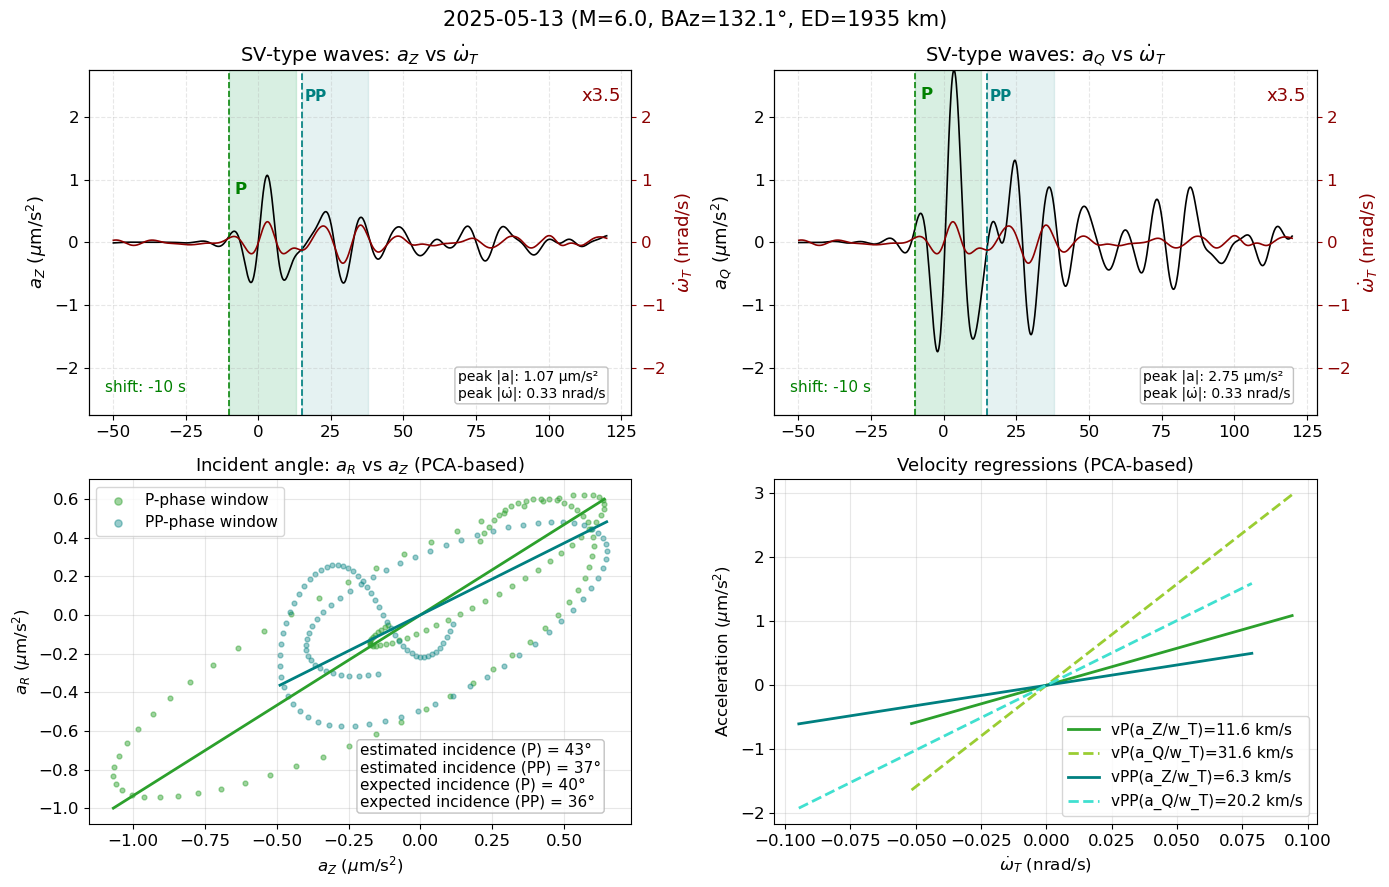

In [45]:
# 3) Plotting
fig2, axes2 = plt.subplots(2, 2, figsize=(14, 9), sharex=False)

##########################################################
# upper-left
ax2_ul = plot_overlay(
    axes2[0, 0], tra_z, rot_t, p_arrival_s, p_window,
    "SV-type waves: $a_Z$ vs $\dot{\omega}_T$",
    "$a_Z$ ($\mu$m/s$^2$)", "$\dot{\omega}_T$ (nrad/s)",
    "P", arrivals_map_P, p_arrival_shift_s,
)

##########################################################
# upper-right
ax2_ur = plot_overlay(
    axes2[0, 1], a_P_Q_trace, rot_t, p_arrival_s, p_window,
    "SV-type waves: $a_Q$ vs $\dot{\omega}_T$",
    "$a_Q$ ($\mu$m/s$^2$)", "$\dot{\omega}_T$ (nrad/s)",
    "P", arrivals_map_P, p_arrival_shift_s,
)

# fallback if stale kernel returns None for ax2
if ax2_ul is None:
    for cand in fig2.axes:
        if cand is not axes2[0, 0] and np.allclose(cand.get_position().bounds, axes2[0, 0].get_position().bounds):
            ax2_ul = cand
            break
if ax2_ur is None:
    for cand in fig2.axes:
        if cand is not axes2[0, 1] and np.allclose(cand.get_position().bounds, axes2[0, 1].get_position().bounds):
            ax2_ur = cand
            break

# shaded windows in upper panels
reg_x0 = reg_w0 - p_arrival_s
reg_x1 = reg_w1 - p_arrival_s
reg2_x0 = reg2_w0 - p_arrival_s
reg2_x1 = reg2_w1 - p_arrival_s
for _ax in [axes2[0, 0], axes2[0, 1]]:
    _ax.axvspan(reg_x0, reg_x1, color="mediumseagreen", alpha=0.20, zorder=0)
    _ax.axvspan(reg2_x0, reg2_x1, color="teal", alpha=0.10, zorder=0)
    _ax.axvline(reg2_x0, color="teal", lw=1.3, ls="--", alpha=0.95)
    _ax.text(reg2_x0 + 1.0, 0.9, f"{second_phase_name}", transform=_ax.get_xaxis_transform(),
             color="teal", fontsize=11, fontweight="bold", va="bottom", ha="left")

# sync y-limits in upper row
yl0 = axes2[0, 0].get_ylim()
yl1 = axes2[0, 1].get_ylim()
ymin_l, ymax_l = min(yl0[0], yl1[0]), max(yl0[1], yl1[1])
axes2[0, 0].set_ylim(ymin_l, ymax_l)
axes2[0, 1].set_ylim(ymin_l, ymax_l)

if ax2_ul is not None and ax2_ur is not None:
    yr0 = ax2_ul.get_ylim()
    yr1 = ax2_ur.get_ylim()
    ymin_r, ymax_r = min(yr0[0], yr1[0]), max(yr0[1], yr1[1])
    ax2_ul.set_ylim(ymin_r, ymax_r)
    ax2_ur.set_ylim(ymin_r, ymax_r)

##########################################################
# lower-left: incident regressions (plot-only)
ax = axes2[1, 0]

ax.scatter(xx_p, yy_p, s=12, color="tab:green", alpha=0.45, label="P-phase window")
if np.isfinite(slope_p_inc):
    xline = np.linspace(np.nanmin(xx_p), np.nanmax(xx_p), 100)
    ax.plot(xline, slope_p_inc * xline, color="tab:green", lw=2)

ax.scatter(xx_x, yy_x, s=12, color="teal", alpha=0.40, label=f"{second_phase_name}-phase window")
if np.isfinite(slope_x_inc):
    xline2 = np.linspace(np.nanmin(xx_x), np.nanmax(xx_x), 100)
    ax.plot(xline2, slope_x_inc * xline2, color="teal", lw=2)

ax.text(
    0.5, 0.04,
    f"estimated incidence (P) = {inc_P_deg:.0f}°\nestimated incidence ({second_phase_name}) = {inc_X_deg:.0f}°\nexpected incidence (P) = {expected_incident_deg:.0f}°\nexpected incidence ({second_phase_name}) = {expected_incident_deg_PP:.0f}°",
    transform=ax.transAxes, va="bottom", ha="left", fontsize=11,
    bbox=dict(boxstyle="round,pad=0.2", facecolor="white", edgecolor="0.7", alpha=0.8),
)

ax.set_title(f"Incident angle: $a_R$ vs $a_Z$ ({slope_method.upper()}-based)", fontsize=13)
ax.set_ylabel("$a_R$ ($\mu$m/s$^2$)", fontsize=12)
ax.set_xlabel("$a_Z$ ($\mu$m/s$^2$)", fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="best", fontsize=11, markerscale=1.5)
ax.tick_params(axis='both', which='major', labelsize=12)

##########################################################
# lower-right: velocity regressions (all 4 datasets; plot-only)
ax = axes2[1, 1]

c_p_az = "tab:green"
c_p_aQ = "yellowgreen"
c_s_az = "teal"
c_s_aQ = "turquoise"

if wt_p.size and azv_p.size:
    # ax.scatter(wt_p, azv_p, s=10, color=c_p_az, alpha=0.45, label="P: $a_Z$ vs $\dot{\omega}_T$")
    if np.isfinite(v_p_az):
        xline = np.linspace(np.nanmin(wt_p), np.nanmax(wt_p), 100)
        ax.plot(xline, v_p_az * xline, color=c_p_az, lw=2, label=f"vP(a_Z/w_T)={v_p_az:.1f} km/s")

if wt_p.size and aQv_p.size:
    # ax.scatter(wt_p, aQv_p, s=10, color=c_p_az, ls="--",alpha=0.45, label="P: $a_Q$ vs $\dot{\omega}_T$")
    if np.isfinite(v_p_aQ):
        xline = np.linspace(np.nanmin(wt_p), np.nanmax(wt_p), 100)
        ax.plot(xline, v_p_aQ * xline, color=c_p_aQ, lw=2, ls="--", label=f"vP(a_Q/w_T)={v_p_aQ:.1f} km/s")

if wt_x.size and azv_x.size:
    label_s_az = second_phase_name + r": $a_Z$ vs $\dot{\omega}_T$"
    # ax.scatter(wt_x, azv_x, s=10, color=c_s_az, alpha=0.45, label=label_s_az)
    if np.isfinite(v_x_az):
        xline2 = np.linspace(np.nanmin(wt_x), np.nanmax(wt_x), 100)
        ax.plot(xline2, v_x_az * xline2, color=c_s_az, lw=2, label=f"v{second_phase_name}(a_Z/w_T)={v_x_az:.1f} km/s")

if wt_x.size and aQv_x.size:
    label_s_aQ = second_phase_name + r": $a_Q$ vs $\dot{\omega}_T$"
    # ax.scatter(wt_x, aQv_x, s=10, color=c_s_az, ls="--", alpha=0.45, label=label_s_aQ)
    if np.isfinite(v_x_aQ):
        xline2 = np.linspace(np.nanmin(wt_x), np.nanmax(wt_x), 100)
        ax.plot(xline2, v_x_aQ * xline2, color=c_s_aQ, lw=2, ls="--", label=f"v{second_phase_name}(a_Q/w_T)={v_x_aQ:.1f} km/s")

ax.set_title(f"Velocity regressions ({slope_method.upper()}-based)", fontsize=13)
ax.set_xlabel("$\dot{\omega}_T$ (nrad/s)", fontsize=12)
ax.set_ylabel("Acceleration ($\mu$m/s$^2$)", fontsize=12)
ax.grid(True, alpha=0.3)
ax.legend(loc="lower right", fontsize=11)
ax.tick_params(axis='both', which='major', labelsize=12)

fig2.suptitle(
    f"{event_date} (M={config['magnitude']:.1f}, BAz={baz:.1f}°, ED={distance_km:.0f} km)",
    fontsize=15,
)
plt.tight_layout()
plt.show()
